# Lecture 17 — Array programming: Turing patterns

We compute a spatial pattern by repeatedly updating two concentration grids. We first use Python loops, then express the same stencil with array operations. The examples show how storage, views, copies and broadcasting affect that implementation.

[Lecture notes](https://teaching.borisbolliet.io/c1-2026/materials/class17/notes.pdf) · [Loop source](https://github.com/borisbolliet/attractor/blob/lecture-17-start/src/attractor/patterns.py) · [Vectorised source](https://github.com/borisbolliet/attractor/blob/lecture-17/src/attractor/patterns.py)

Run the cells in order with NumPy and Matplotlib installed. The functions below are included in the notebook, so a downloaded copy does not require an `attractor` installation. Timings are measured when the cells run.

In [1]:
%matplotlib inline
import platform
import time
import numpy as np
import matplotlib.pyplot as plt

print('Python', platform.python_version())
print('NumPy', np.__version__)

def seconds(function, *args, repeat=5):
    """Median elapsed time after one untimed call."""
    function(*args)
    durations = []
    for _ in range(repeat):
        start = time.perf_counter()
        function(*args)
        durations.append(time.perf_counter() - start)
    return float(np.median(durations))

Python 3.13.11
NumPy 2.5.4


## 1. Reaction–diffusion patterns

### 1.1. The Gray–Scott model

The dimensionless concentrations $u$ and $v$ describe two chemicals, $U$ and $V$. The reaction $U+2V\to3V$ consumes $U$ and produces $V$. Diffusion transports material between neighbouring points. The constants $D_u,D_v$ are diffusion coefficients, $F$ is a feed rate and $k$ is an additional removal rate for $V$.

$$\partial_t u=D_u\nabla^2u-uv^2+F(1-u),\qquad
\partial_t v=D_v\nabla^2v+uv^2-(F+k)v.$$

Here $\nabla^2=\partial_x^2+\partial_y^2$ is the Laplacian. The diffusion terms are linear in the concentrations. The reaction term $uv^2$ is nonlinear: doubling $v$ with $u$ fixed multiplies it by four. The feed term also contains the constant source $F$.

We store each concentration in a two-dimensional array. In `u[i, j]`, `i` selects the row and `j` the column of the spatial grid. Periodic boundaries join opposite edges: a neighbour beyond the last column is in the first column.

Outside a central 16×16 square, $u=1$ and $v=0$. Inside it, $u=0.5$ and $v=0.25$, with uniform noise between $-0.01$ and $0.01$. This finite disturbance seeds the patterns. It is not a test of instability to infinitesimal perturbations of a uniform state.

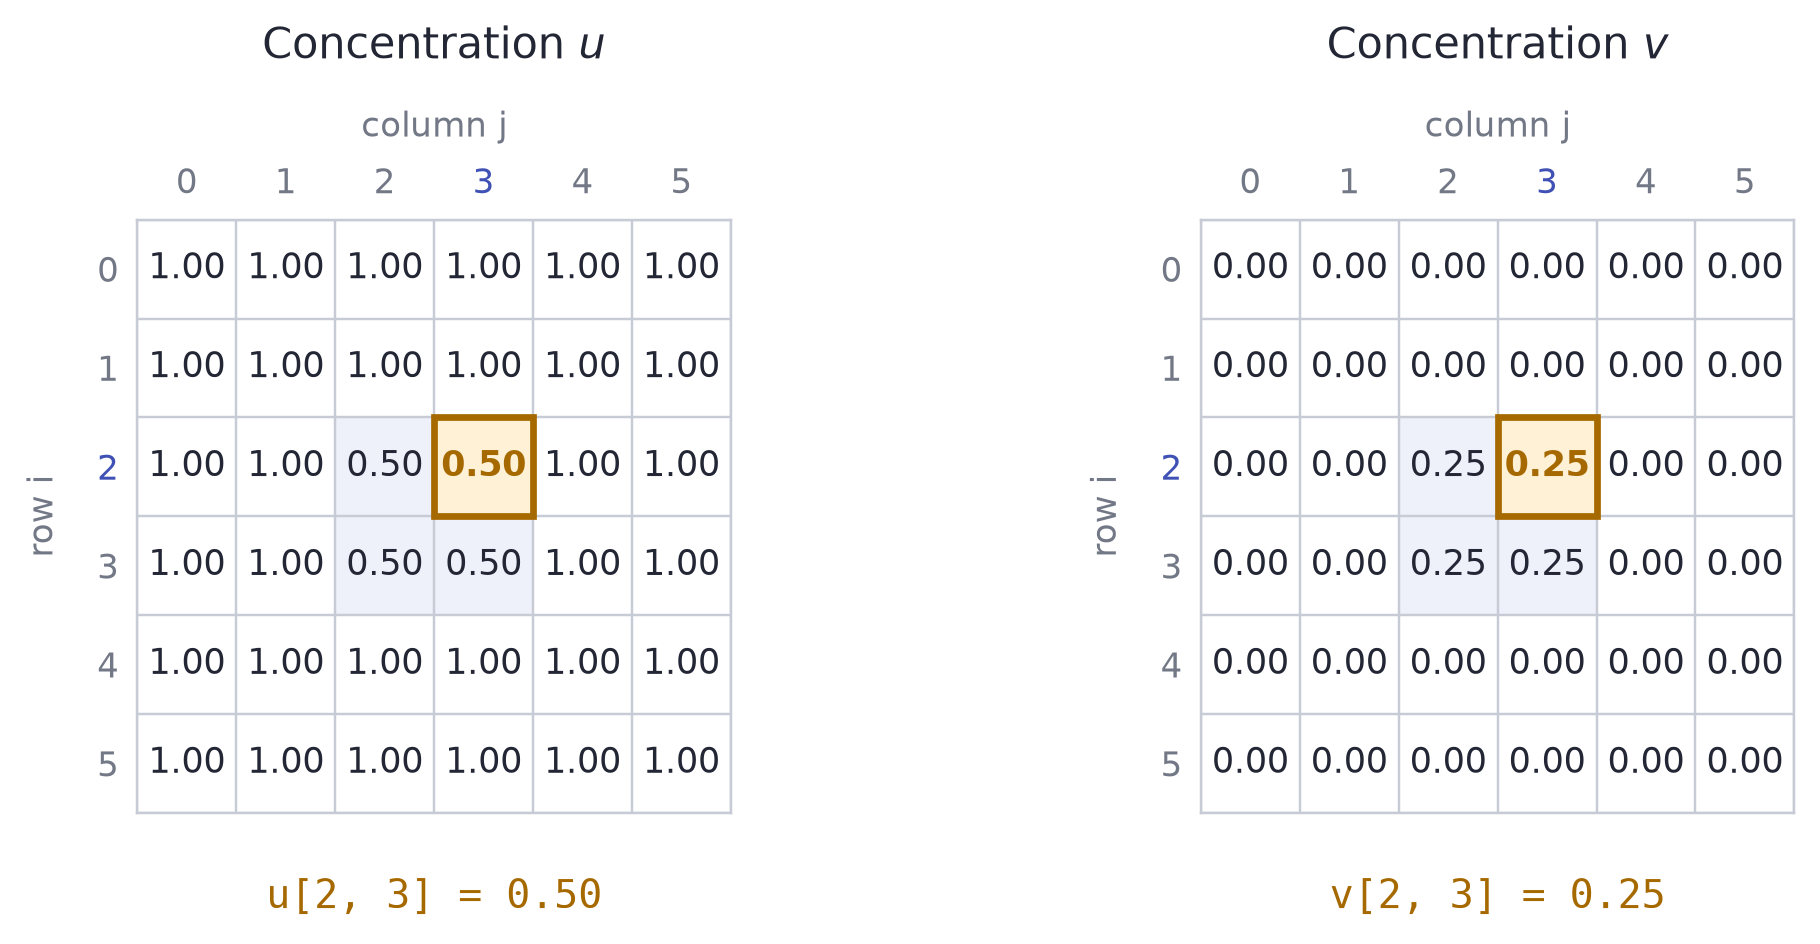

The same spatial point is represented by one entry in each concentration array, u and v.

shapes: (256, 256) (256, 256)
central values: 0.5063624194194182 0.2538254295888121


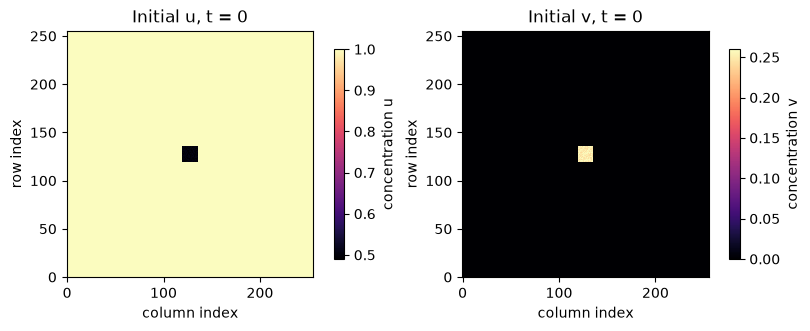

In [2]:
SPOTS = (0.030, 0.062)
STRIPES = (0.040, 0.060)

def initial(n, seed=0, batch=()):
    """u = 1 and v = 0, except a central square of u = 0.5 and v = 0.25, with bounded noise in that square.

    ``batch`` is the shape of the batch axes; every grid of the batch starts
    from different noise.
    """
    rng = np.random.default_rng(seed)
    u, v = np.ones(batch + (n, n)), np.zeros(batch + (n, n))
    c = slice(n // 2 - 8, n // 2 + 8)
    u[..., c, c], v[..., c, c] = 0.50, 0.25
    u[..., c, c] += rng.uniform(-0.01, 0.01, u[..., c, c].shape)
    v[..., c, c] += rng.uniform(-0.01, 0.01, v[..., c, c].shape)
    return u, v

u, v = initial(256)
assert u.min() >= 0 and v.min() >= 0
print('shapes:', u.shape, v.shape)
print('central values:', u[128, 128], v[128, 128])

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), layout='constrained')
for ax, field, name in zip(axes, [u, v], ['u', 'v']):
    im = ax.imshow(field, cmap='magma', origin='lower', interpolation='nearest')
    ax.set_title(f'Initial {name}, t = 0')
    ax.set_xlabel('column index')
    ax.set_ylabel('row index')
    fig.colorbar(im, ax=ax, label=f'concentration {name}', shrink=0.85)
plt.show()

### 1.2. Five-point stencil

Let $a$ be either concentration array, $u$ or $v$. The grid spacing $h$ is the distance between neighbouring points, the same in both directions. We write $L_h$ for the discrete Laplacian:

$$(\nabla^2a)_{i,j}\approx(L_h a)_{i,j}
=\frac{a_{i-1,j}+a_{i+1,j}+a_{i,j-1}+a_{i,j+1}-4a_{i,j}}{h^2}.$$

The factor $1/h^2$ comes from approximating a second derivative: we divide by distance twice. Our code uses $h=1$. A **stencil** is the fixed arrangement of points used in this calculation; here these are the centre and its four nearest neighbours.

The `%` operator wraps a neighbour index at a periodic boundary. For example, `(-1) % 3` is 2, the final row of a three-row array.

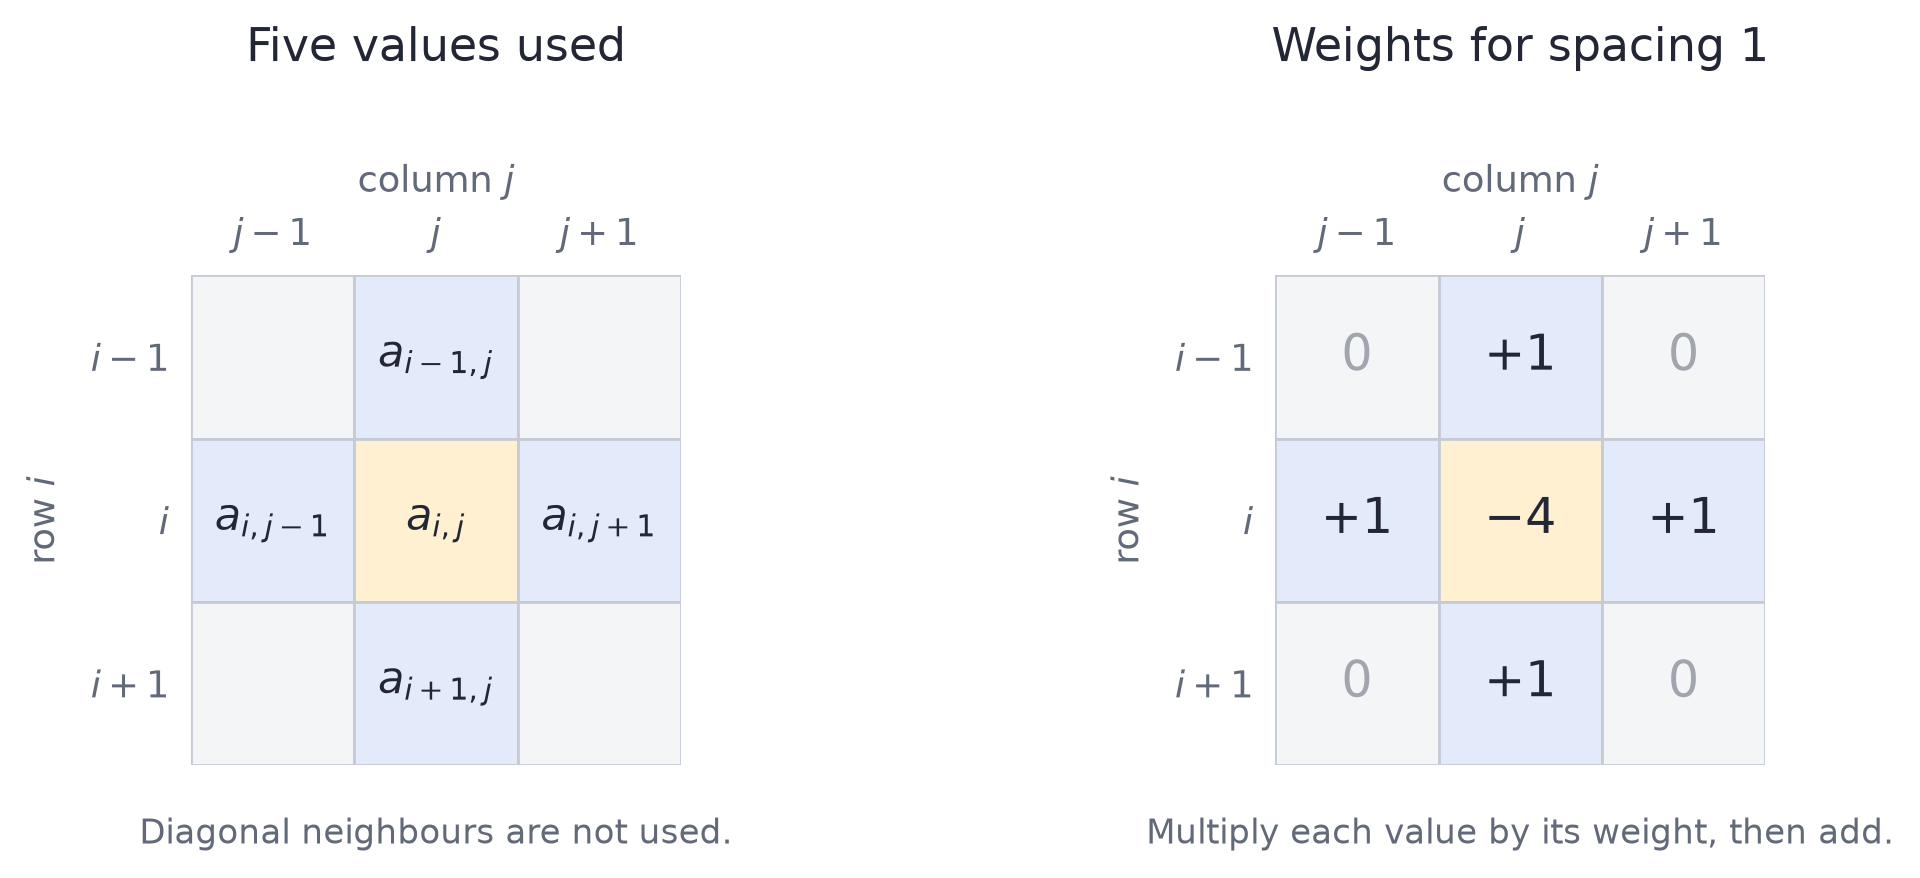

For h = 1, the four neighbours have weight +1 and the centre has weight −4. Diagonal neighbours do not contribute.

In [3]:
def laplacian_loops(a):
    """Five-point Laplacian of the 2-D array a, with periodic boundaries.

    Examples
    --------
    >>> a = np.zeros((3, 3)); a[1, 1] = 1.0
    >>> print(laplacian(a))
    [[ 0.  1.  0.]
     [ 1. -4.  1.]
     [ 0.  1.  0.]]
    """
    n0, n1 = a.shape
    out = np.empty_like(a)
    for i in range(n0):
        for j in range(n1):
            out[i, j] = (a[(i - 1) % n0, j] + a[(i + 1) % n0, j]
                         + a[i, (j - 1) % n1] + a[i, (j + 1) % n1] - 4 * a[i, j])
    return out

impulse = np.zeros((3, 3))
impulse[1, 1] = 1.0
print(laplacian_loops(impulse))

[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]


The centre becomes −4 and its four neighbours become 1. We can also express this operation as a matrix product, as in the notes, §1.2.1.

#### Matrix representation

For a 4×4 concentration array $a$, flattening row by row gives a vector $\boldsymbol b$ of 16 values. The Laplacian matrix $L$ has shape 16×16. Row $q$ specifies the calculation at grid point $q$: coefficient −4 for that point and +1 for each of its four periodic neighbours.

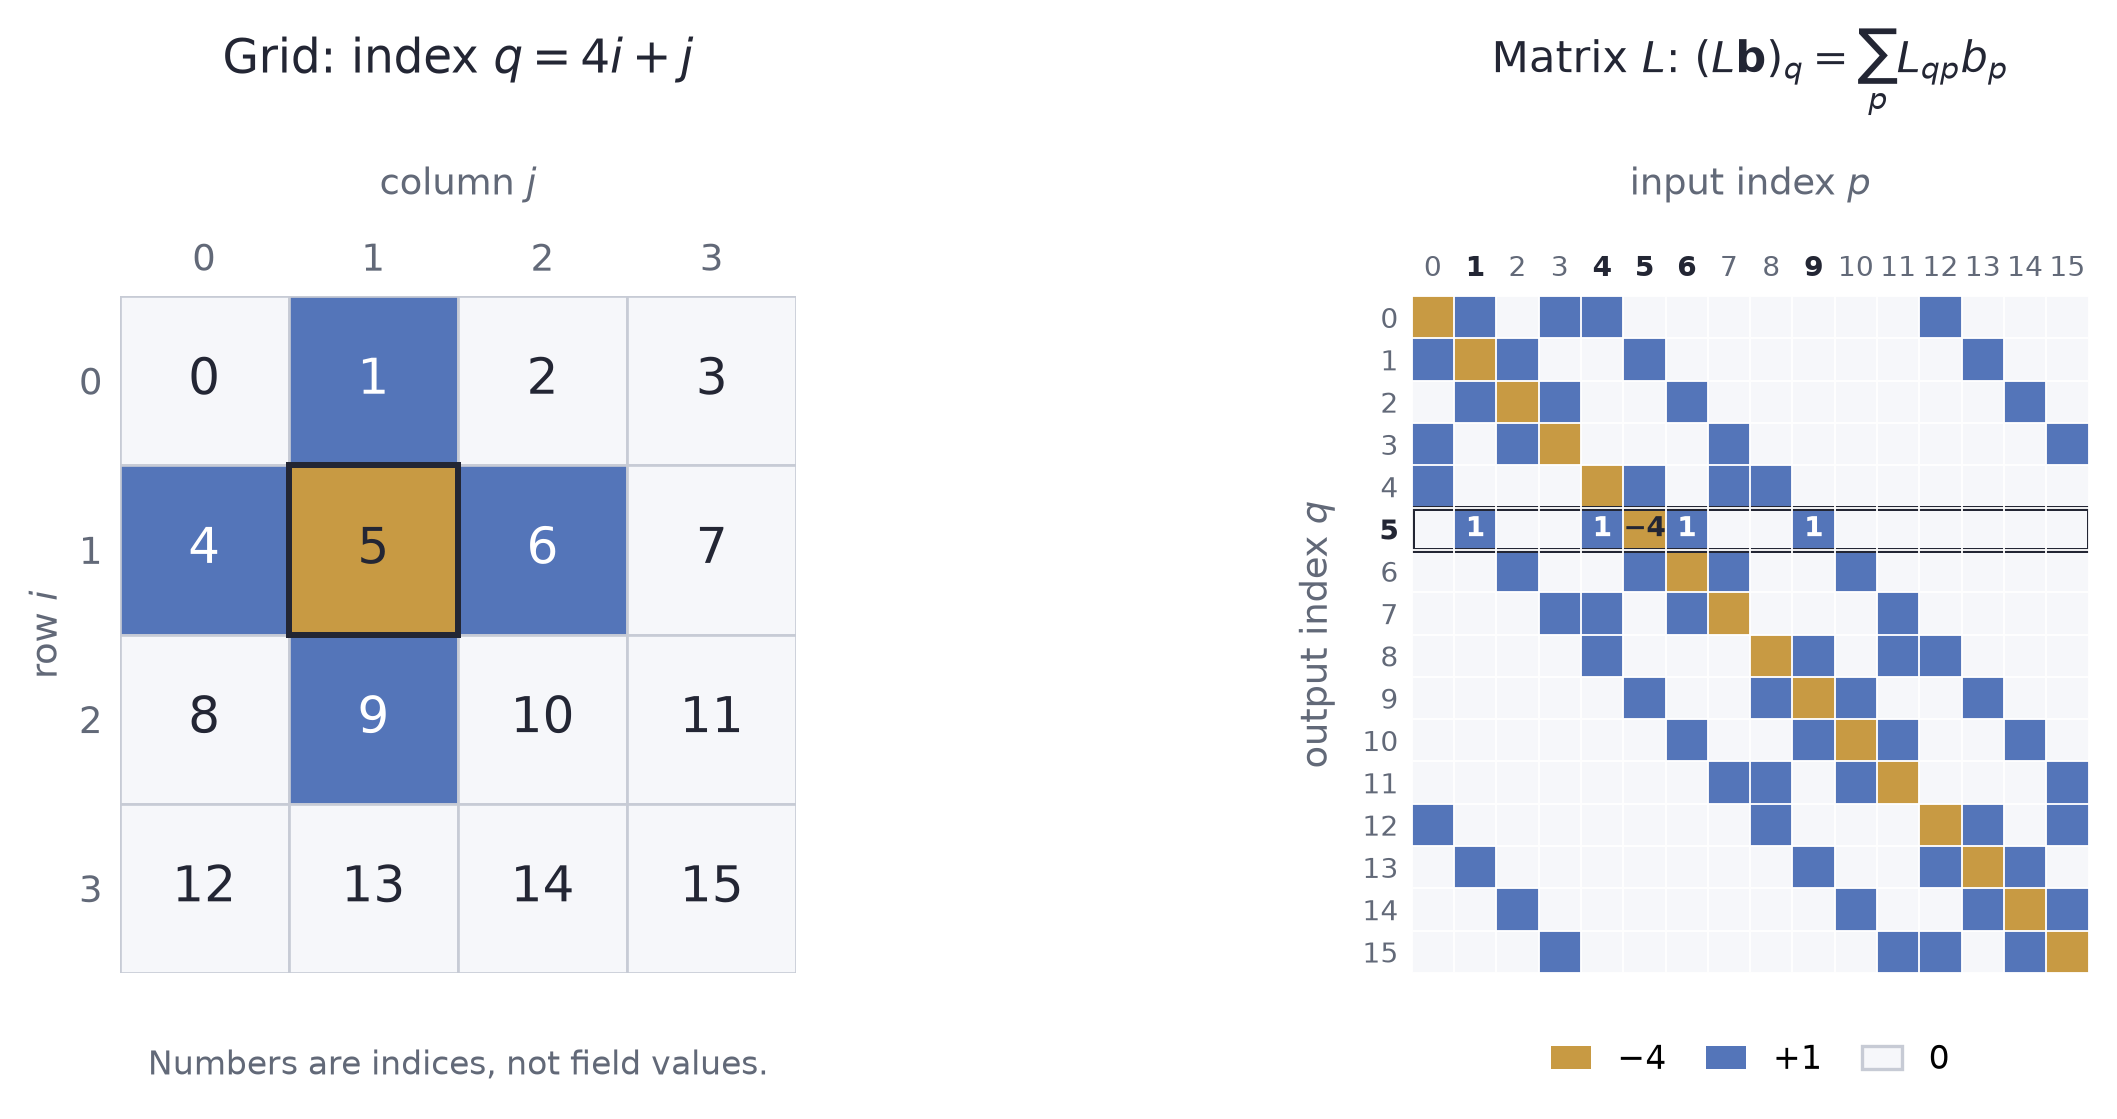

Point (1, 1) has flattened index 5. Row 5 of L combines entries 1, 4, 5, 6 and 9 of the flattened vector b.

In [4]:
n = 4
a = np.arange(n * n, dtype=float).reshape(n, n)
L = np.zeros((n * n, n * n))
for i in range(n):
    for j in range(n):
        q = n * i + j
        L[q, q] = -4
        for row, column in [((i - 1) % n, j), ((i + 1) % n, j),
                            (i, (j - 1) % n), (i, (j + 1) % n)]:
            L[q, n * row + column] += 1

b = a.reshape(n * n)
d = L @ b
print('a.shape:', a.shape, 'L.shape:', L.shape)
print('row 5 uses columns:', np.flatnonzero(L[5]))
print('Laplacian restored to grid shape:')
print(d.reshape(n, n))
np.testing.assert_array_equal(d.reshape(n, n), laplacian_loops(a))
assert d[5] == laplacian_loops(a)[1, 1]

a.shape: (4, 4) L.shape: (16, 16)
row 5 uses columns: [1 4 5 6 9]
Laplacian restored to grid shape:
[[ 20.  16.  16.  12.]
 [  4.   0.   0.  -4.]
 [  4.   0.   0.  -4.]
 [-12. -16. -16. -20.]]


Each entry of $\boldsymbol d=L\boldsymbol b$ is one computed Laplacian value. Reshaping places it back at its grid position: `d[5]` becomes entry `[1, 1]`. The dense matrix here is small enough to display, but its storage grows as $N^2$ for $N$ grid points. Direct stencil evaluation uses five values per point and does not construct this matrix.

#### Applying and timing an Euler step

Forward Euler advances the simulated time by $\Delta t$, written `dt` in Python. The new concentration equals the current concentration plus `dt` times its rate of change. Both new arrays must be computed from the same old state. The intermediate `uvv` below contains the reaction rates $uv^2$.

For $N$ grid points, each Laplacian takes $\Theta(N)$ work: a fixed amount per point. Each Euler step also takes $\Theta(N)$ work, and $S$ steps take $\Theta(SN)$ work. Doubling both grid dimensions gives four times as many points. This uses the operation counting of [L6, §§3.4 and 4.2](https://teaching.borisbolliet.io/c1-2026/materials/class06/notes.pdf#page=8).

We time one step before attempting a long simulation. The helper `seconds` makes one untimed call, then returns the median of the timed calls.

In [5]:
def step_loops(u, v, F, k, Du=0.16, Dv=0.08, dt=1.0):
    """One forward Euler step of the Gray-Scott equations; returns new arrays.

    F and k are numbers, or arrays that broadcast against u and v.
    The pure-diffusion Euler bound is max(Du, Dv) * dt <= 1/4.
    Reactions can impose an additional restriction.
    """
    uvv = u * v * v
    return (u + dt * (Du * laplacian_loops(u) - uvv + F * (1 - u)),
            v + dt * (Dv * laplacian_loops(v) + uvv - (F + k) * v))

t_loop_step = seconds(step_loops, u, v, *SPOTS, repeat=3)
print(f'One 256 x 256 step: {1e3 * t_loop_step:.2f} ms')
print(f'Estimated time for 10,000 such steps: {t_loop_step * 10_000 / 60:.1f} min')

One 256 x 256 step: 54.91 ms
Estimated time for 10,000 such steps: 9.2 min


Each of the two Laplacian calls visits all 65,536 grid points in Python. Repeated indexing, remainder calculations and NumPy scalar arithmetic make this inefficient for a long simulation. Vectorisation will keep the same stencil and its $\Theta(N)$ work per step, while moving these numerical loops into compiled code.

## 2. Arrays in memory

### 2.1. Shape, dtype and strides

A NumPy array represents values of one data type in memory. Its **dtype** specifies that type, and its **shape** gives the length of each axis. The values are held in a data **buffer**, which several arrays may share.

The **strides** give the change in memory address, in bytes, when one index increases by one. In this example, float64 occupies eight bytes and a row contains four values. `itemsize` is the number of bytes per value; `nbytes` is `size * itemsize`, the bytes occupied by this array's elements.

In [6]:
a = np.arange(12.0).reshape(3, 4)
print(a)
print(a.dtype, a.itemsize, a.shape, a.strides, a.nbytes)
assert a.strides == (32, 8)

[[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]]
float64 8 (3, 4) (32, 8) 96


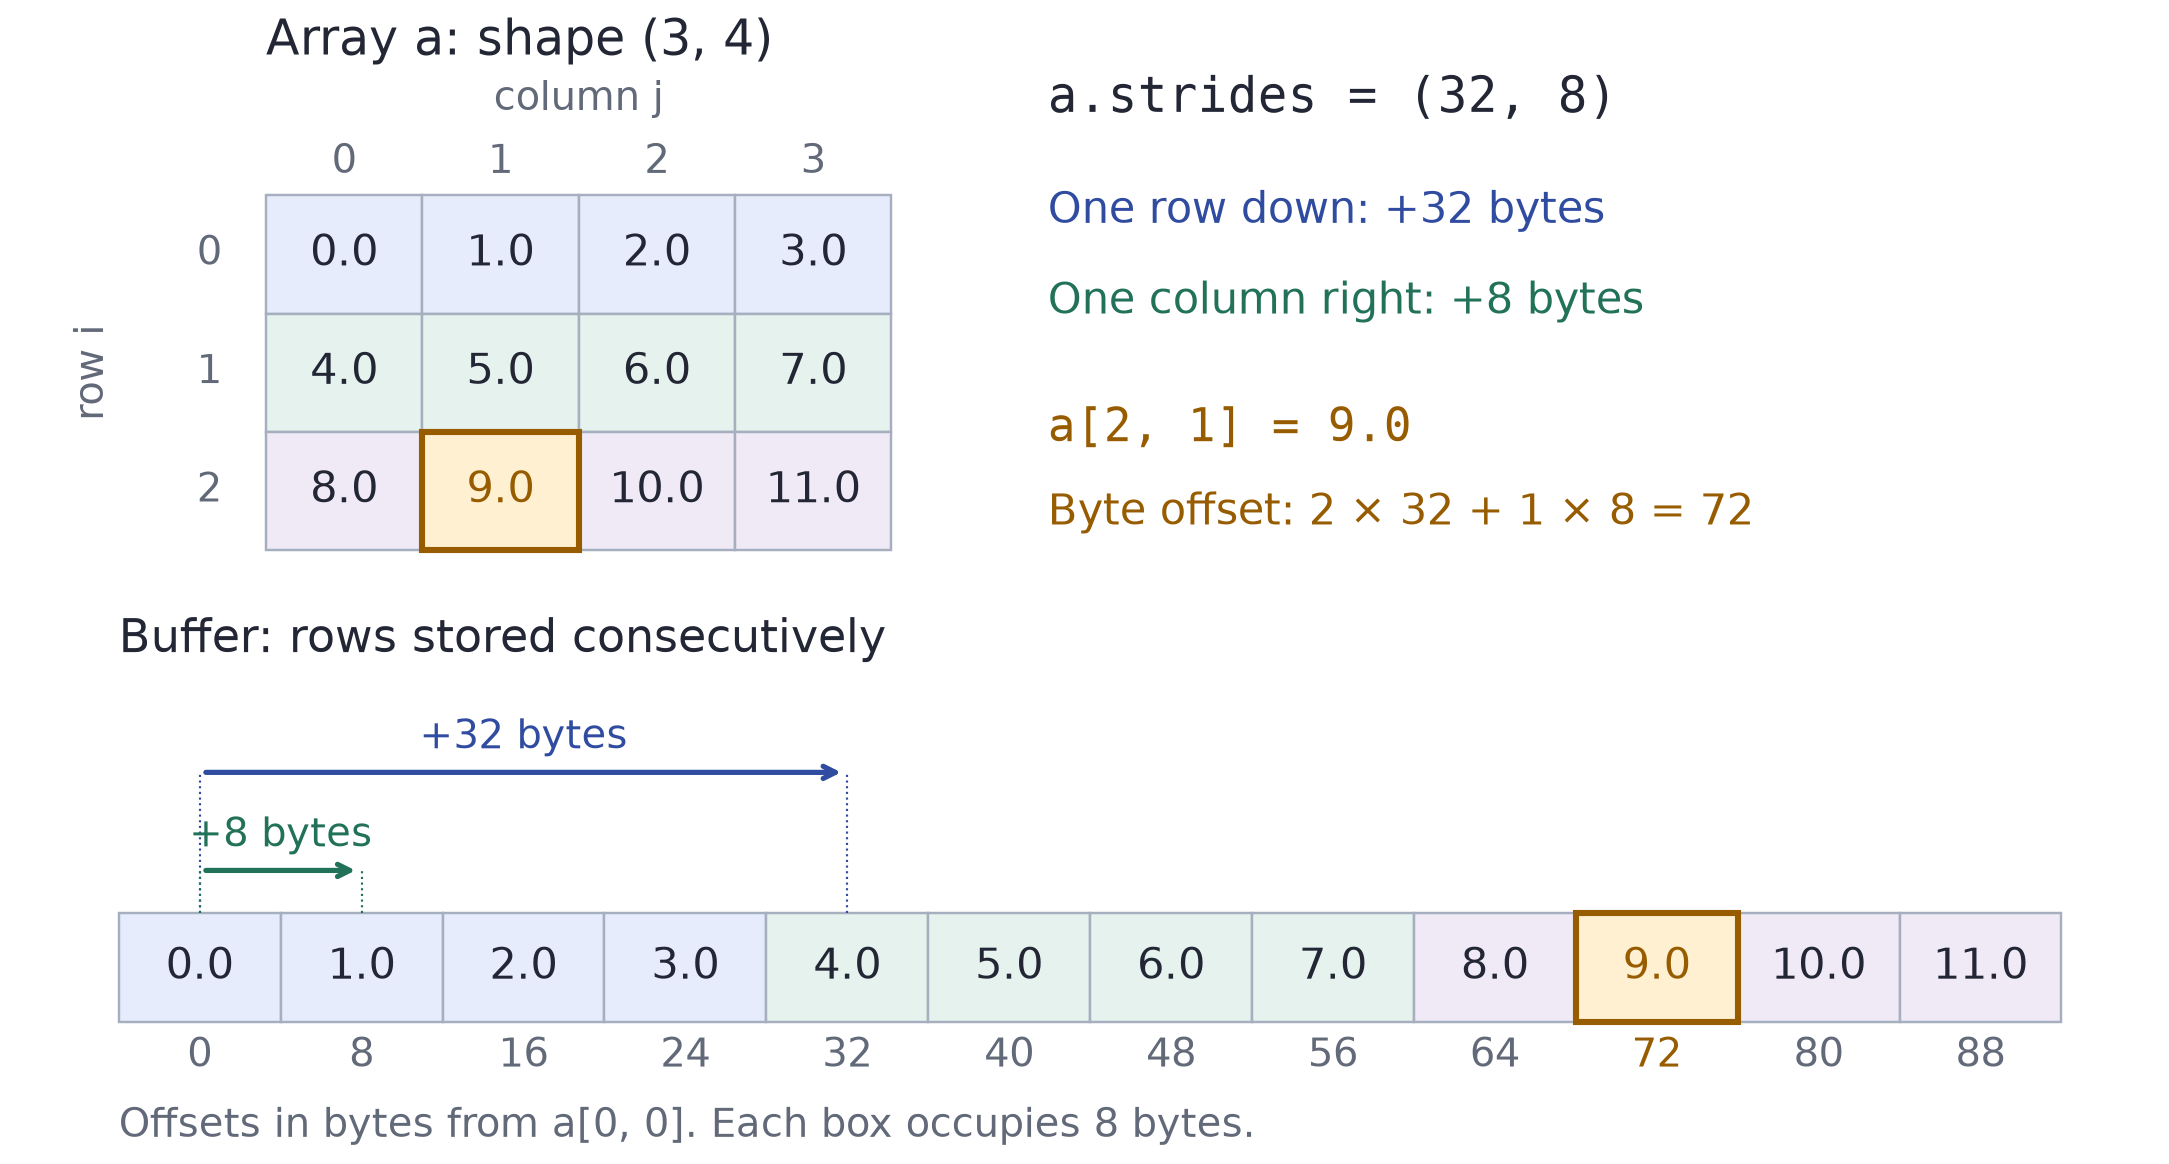

Increasing the column index by one changes the address by 8 bytes. Increasing the row index by one changes it by 32 bytes.

Rows occupy consecutive memory locations: C or **row-major** order. The offset of `a[i, j]` from `a[0, 0]` is $32i+8j$ bytes. For `(2, 1)`, the offset is 72 bytes.

In [7]:
i, j = 2, 1
offset = i * a.strides[0] + j * a.strides[1]
print('byte offset:', offset, 'value:', a[i, j])
assert offset == 72 and a[i, j] == 9
for dtype in (np.uint8, np.float16, np.float32, np.float64):
    itemsize = np.dtype(dtype).itemsize
    print(f'{np.dtype(dtype).name:8s}: {itemsize} bytes/value, {256*256*itemsize/1024:.0f} KiB/grid')

byte offset: 72 value: 9.0
uint8   : 1 bytes/value, 64 KiB/grid
float16 : 2 bytes/value, 128 KiB/grid
float32 : 4 bytes/value, 256 KiB/grid
float64 : 8 bytes/value, 512 KiB/grid


### 2.2. Views

A **view** is a new array object that shares stored data with another array. It has its own shape, strides and starting position (see also [L9, §1.5](https://teaching.borisbolliet.io/c1-2026/materials/class09/notes.pdf#page=7)). The slice below selects two columns. Its rows still start 32 bytes apart, leaving gaps where the omitted columns lie.

`nbytes` counts this array's elements (`size * itemsize`); it does not measure the entire shared allocation.

In [8]:
b = a[:, 1:3]
print(b)
print('shape, strides:', b.shape, b.strides)
print('element bytes:', a.nbytes, b.nbytes)
print('shared memory:', np.shares_memory(a, b))
print('distinct array objects:', b is not a)
assert b.nbytes == 48 and a.nbytes == 96
assert b is not a and np.shares_memory(a, b)

[[ 1.  2.]
 [ 5.  6.]
 [ 9. 10.]]
shape, strides: (3, 2) (32, 8)
element bytes: 96 48
shared memory: True
distinct array objects: True


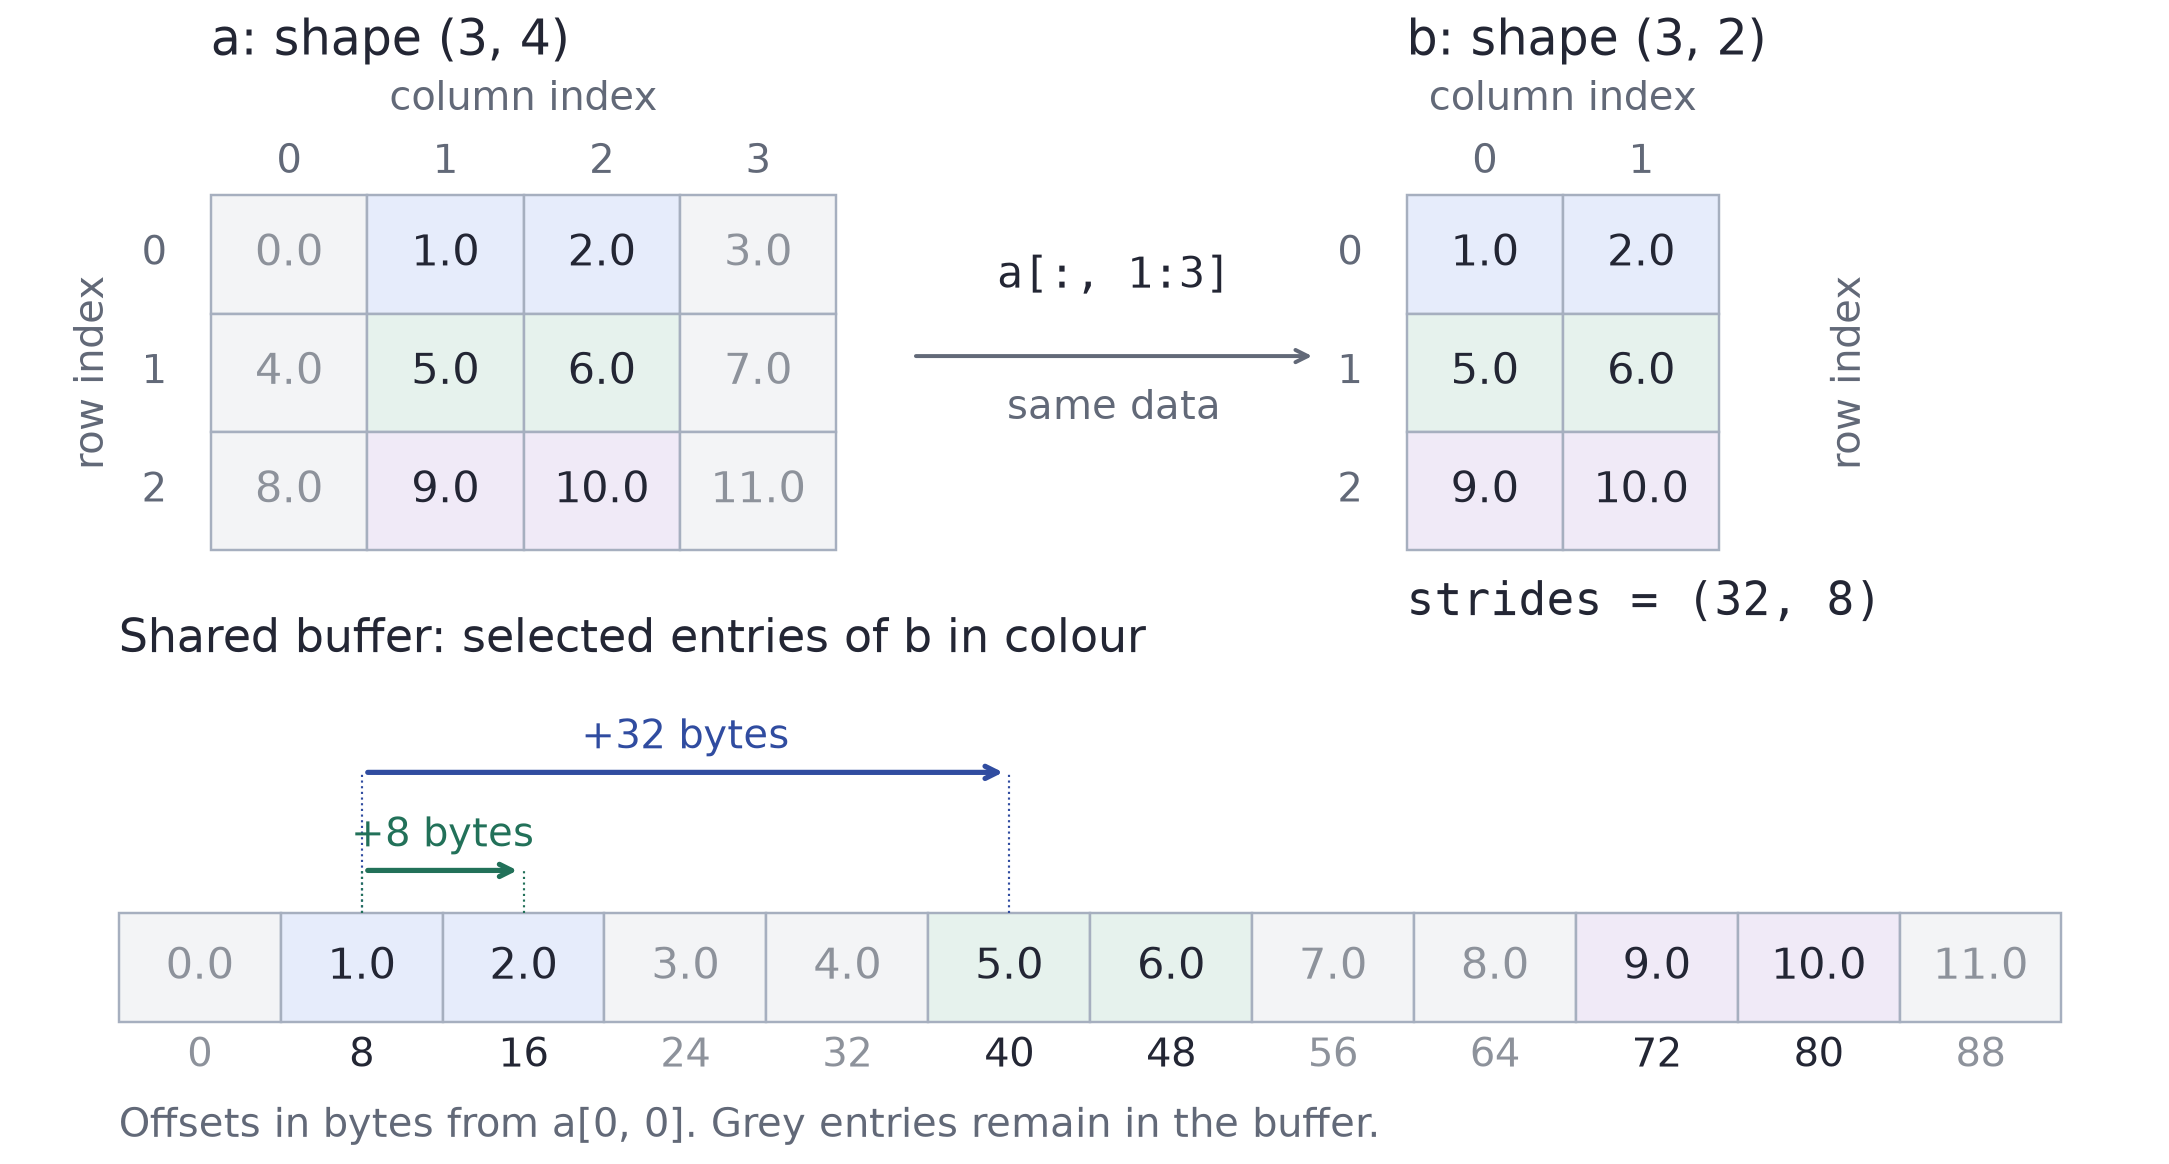

The view selects the middle two columns. Their values stay at the same addresses in the original buffer; the row and column strides remain (32, 8).

The two arrays share these values, so writing through `b` also changes the corresponding entry of `a`:

In [9]:
b[0, 0] = -1.0
print('a[0, 1] after writing through b:', a[0, 1])
assert a[0, 1] == -1

a[0, 1] after writing through b: -1.0


Transposing swaps the two axes and their strides. Selecting every second column doubles the column stride. Reversing columns starts at the last column and moves backwards through each row.

In [10]:
for name, view in [('transpose', a.T), ('every second column', a[:, ::2]), ('reversed columns', a[:, ::-1])]:
    print(name, 'shape', view.shape, 'strides', view.strides)
    assert np.shares_memory(a, view)

transpose shape (4, 3) strides (8, 32)
every second column shape (3, 2) strides (32, 16)
reversed columns shape (3, 4) strides (32, -8)


### 2.3. Copies and assignment

A copy has separate storage. Ordinary arithmetic such as `a * 1` also allocates a result. Reading with a list or array of indices is **advanced indexing** and copies the selected values. In-place arithmetic such as `a *= 2` instead writes into the existing array.

In [11]:
a = np.arange(12.0).reshape(3, 4)
c = a.copy()
c[0, 0] = -9.0
print('original:', a[0, 0], 'copy:', c[0, 0])
for name, value in [('a[[0, 2]]', a[[0, 2]]), ('a * 1', a * 1)]:
    print(name, 'shares memory:', np.shares_memory(a, value))
assert not np.shares_memory(a, c)

original: 0.0 copy: -9.0
a[[0, 2]] shares memory: False
a * 1 shares memory: False


We can reshape the twelve values into two rows of six without moving them. The values stay in their original order and at the same memory addresses. The new row stride is `6 * 8 = 48` bytes:

In [12]:
r = a.reshape(2, 6)
print(r)
print('strides:', r.strides, 'shared memory:', np.shares_memory(a, r))
assert r.strides == (48, 8) and np.shares_memory(a, r)

[[ 0.  1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10. 11.]]
strides: (48, 8) shared memory: True


Now transpose `a` before reshaping it into one dimension. By default, `reshape` reads its input row by row. The first row of `a.T` contains 0, 4 and 8, and the second contains 1, 5 and 9:

In [13]:
print('transpose:')
print(a.T)
flat = a.T.reshape(12)
print('flattened transpose:', flat)
print('strides:', flat.strides, 'shared memory:', np.shares_memory(a, flat))
assert flat.strides == (8,) and not np.shares_memory(a, flat)
np.testing.assert_array_equal(flat, [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11])

transpose:
[[ 0.  4.  8.]
 [ 1.  5.  9.]
 [ 2.  6. 10.]
 [ 3.  7. 11.]]
flattened transpose: [ 0.  4.  8.  1.  5.  9.  2.  6. 10.  3.  7. 11.]
strides: (8,) shared memory: False


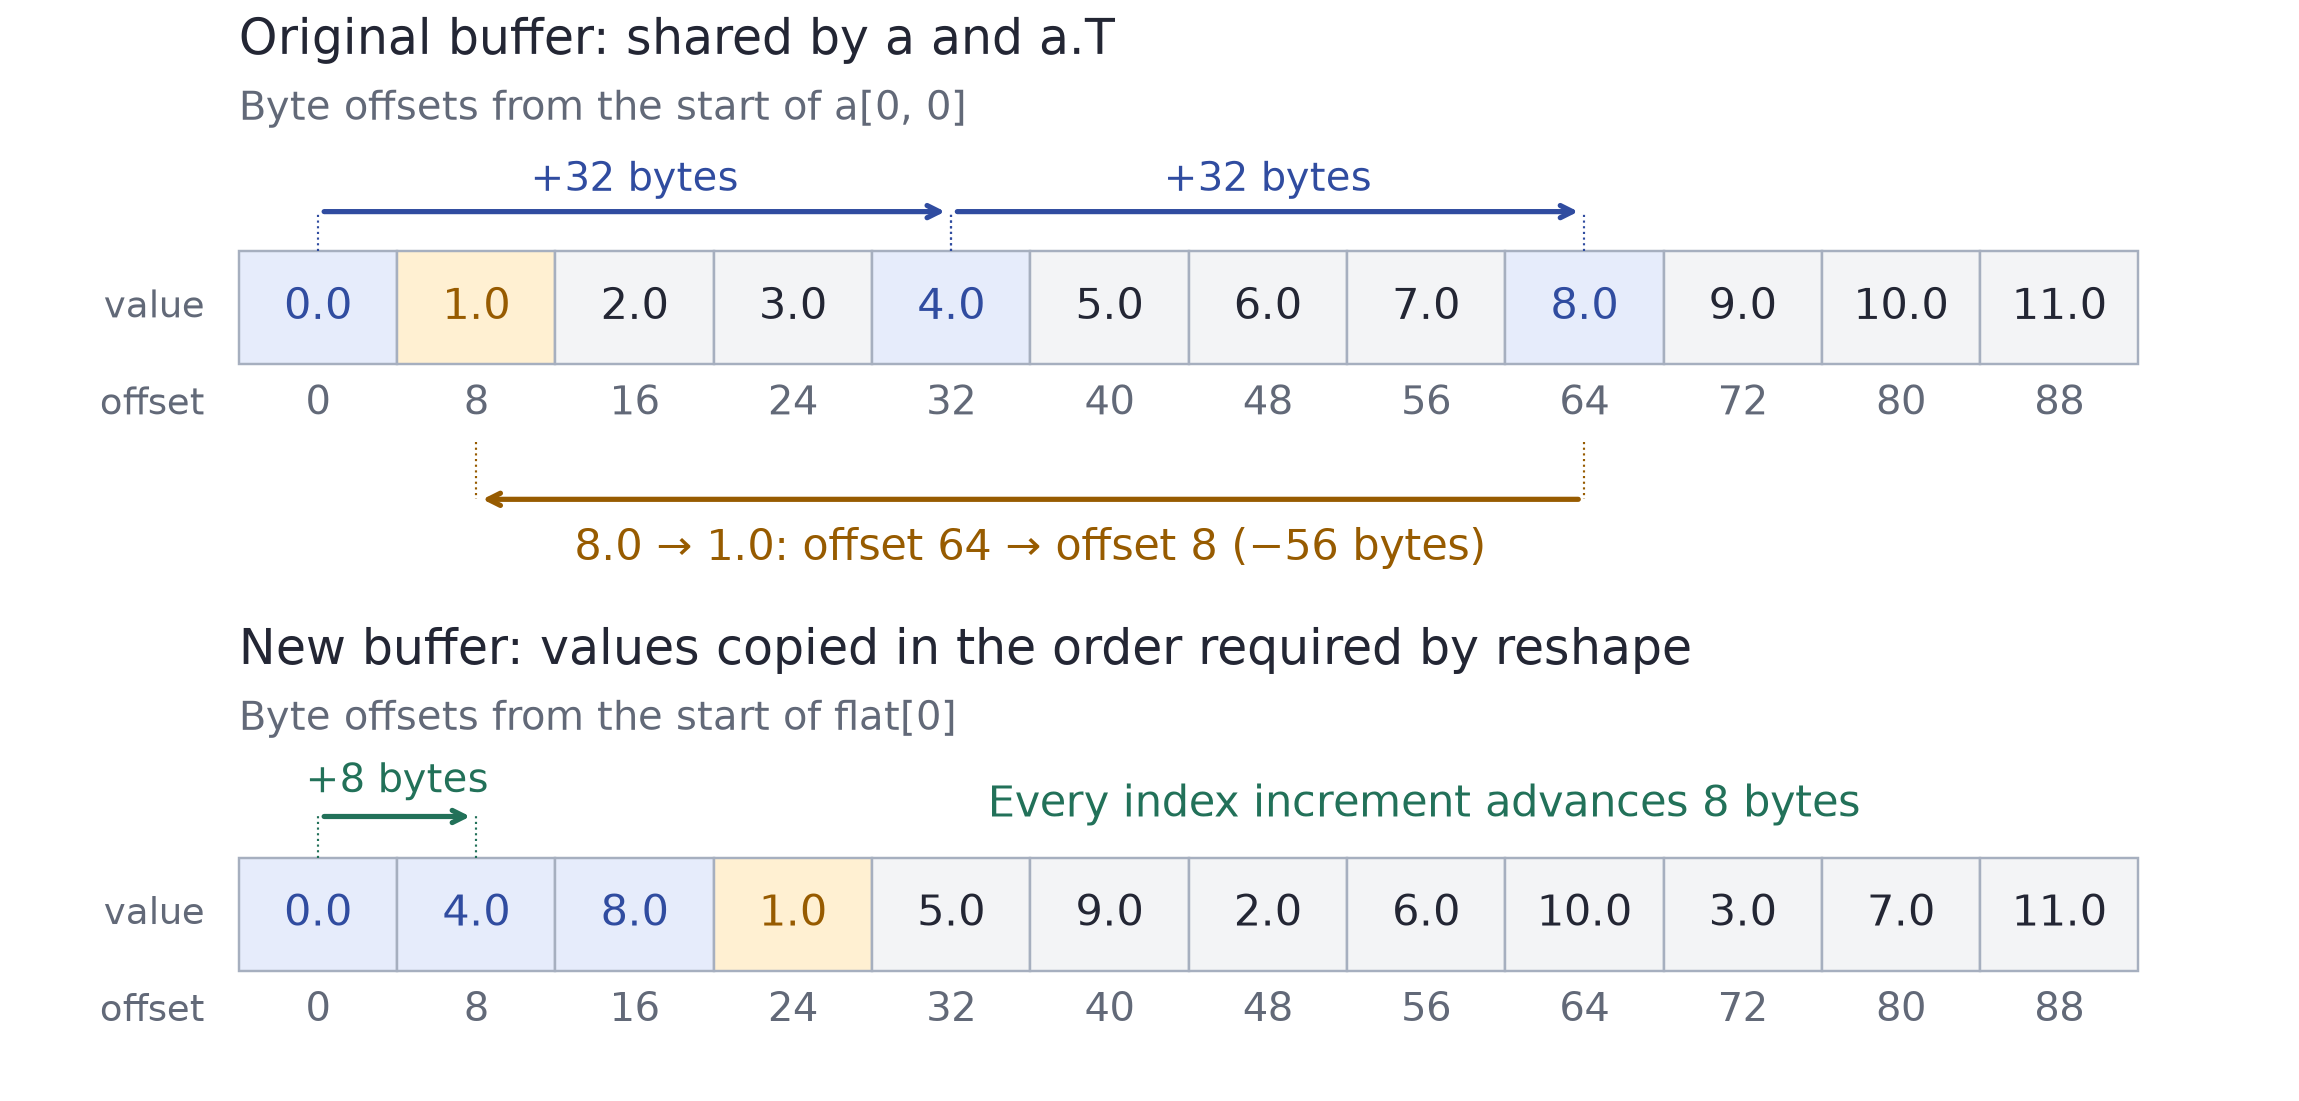

The requested order first moves forward by 32 bytes, then backwards from offset 64 to offset 8. The new buffer holds these values consecutively.

In the original buffer, 0, 4 and 8 start at offsets 0, 32 and 64 bytes. The next required value, 1, starts at offset 8: reading it after 8 requires a change of $8-64=-56$ bytes. A one-dimensional view has one fixed stride, so it cannot describe both changes of address. NumPy copies the values into the requested order, with stride 8 in the new buffer.

We should also distinguish reading indexed values from assigning to them. In `a[[0, 2]][0, 0] = -1`, the first indexing operation copies rows 0 and 2. The second indexing operation writes into that copy. We can make the intermediate array explicit:

In [14]:
a = np.arange(12.0).reshape(3, 4)
tmp = a[[0, 2]]
print('selected rows:')
print(tmp)
print('shared memory:', np.shares_memory(a, tmp))
tmp[0, 0] = -1.0
print('tmp[0, 0]:', tmp[0, 0], 'a[0, 0]:', a[0, 0])
assert tmp[0, 0] == -1 and a[0, 0] == 0

a[[0, 2]][0, 0] = -1.0
print('after the one-line expression:', a[:, 0])
np.testing.assert_array_equal(a[:, 0], [0, 4, 8])

selected rows:
[[ 0.  1.  2.  3.]
 [ 8.  9. 10. 11.]]
shared memory: False
tmp[0, 0]: -1.0 a[0, 0]: 0.0
after the one-line expression: [0. 4. 8.]


In `a[[0, 2], 0] = -1`, we supply the row and column indices together as the target of one assignment. NumPy writes directly to `a[0, 0]` and `a[2, 0]`:

In [15]:
a[[0, 2], 0] = -1.0
print(a)
np.testing.assert_array_equal(a[:, 0], [-1, 4, -1])

[[-1.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [-1.  9. 10. 11.]]


Reading with the same index, as in `selected = a[[0, 2], 0]`, would produce a copy. With basic slicing, an intermediate array is a view: the following chained assignment therefore changes `a[0, 1]`.

In [16]:
a[:, 1:3][0, 0] = -2.0
print('a[0, 1] after writing through a slice:', a[0, 1])
assert a[0, 1] == -2

a[0, 1] after writing through a slice: -2.0


### 2.4. Moving axes and the ellipsis

An **axis** corresponds to one position in an array index. For a colour image stored as `fields[channel, row, column]`, axes 0, 1 and 2 select the channel, row and column. The array has three dimensions, although the image has only two spatial dimensions.

Matplotlib's `imshow` expects `(row, column, channel)`. `np.moveaxis(fields, 0, -1)` moves axis 0 to the last position, keeping the row and column axes in their relative order. We could write `2` instead of `-1` here.

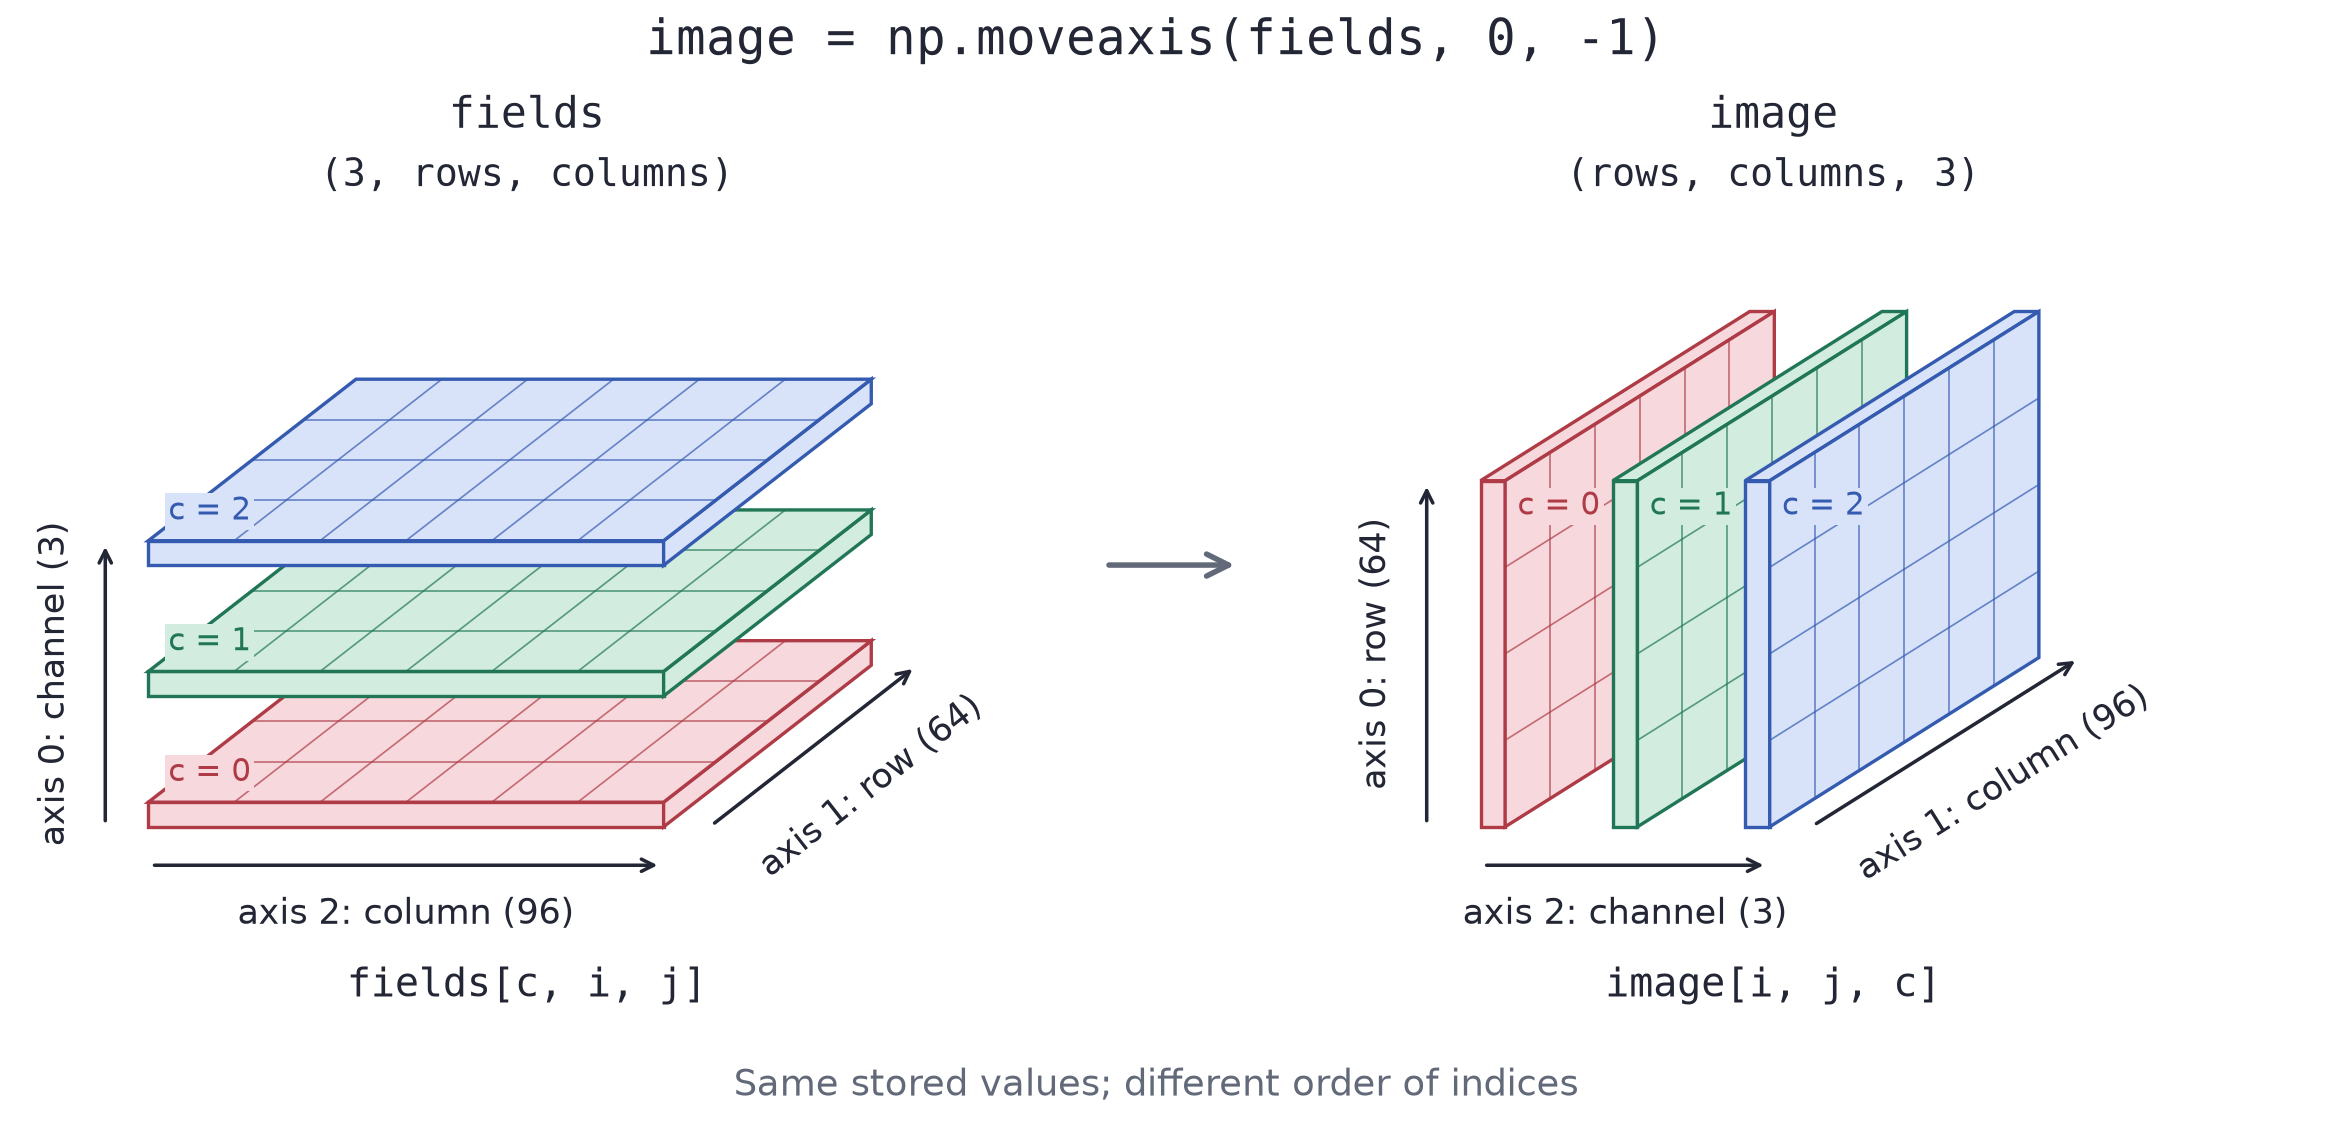

The three colour planes are shown apart for visibility. Moving the channel axis changes the indexing order, not the memory locations of the values.

In [17]:
fields = np.zeros((3, 64, 96))
fields[1, 2, 3] = 0.5
image = np.moveaxis(fields, 0, -1)
print('image:', image.shape, image.strides)
print('same stored value:', fields[1, 2, 3], image[2, 3, 1])
assert image.shape == (64, 96, 3) and np.shares_memory(fields, image)
assert image[2, 3, 1] == 0.5
np.testing.assert_array_equal(np.moveaxis(image, -1, 0), fields)

image: (64, 96, 3) (768, 8, 49152)
same stored value: 0.5 0.5


We use the **ellipsis**, `...`, to keep all elements along the axes we have not specified explicitly. For this three-dimensional array, `fields[..., 1:-1]` means `fields[:, :, 1:-1]`: keep all channels and rows, but exclude the first and last columns. In `fields[0, ..., 0]`, the ellipsis replaces only one slice, giving `fields[0, :, 0]`.

In [18]:
print('last-axis interior:', fields[..., 1:-1].shape)
print('first channel and first column:', fields[0, ..., 0].shape)
assert fields[..., 1:-1].shape == (3, 64, 94)
np.testing.assert_array_equal(fields[..., 1:-1], fields[:, :, 1:-1])
np.testing.assert_array_equal(fields[0, ..., 0], fields[0, :, 0])

last-axis interior: (3, 64, 94)
first channel and first column: (64,)


## 3. Vectorising the stencil

### 3.1. Operations on whole arrays

**Vectorisation** expresses a calculation using whole-array operations. For numeric arrays, NumPy executes the elementwise loops in compiled code.

For example, `a * a` multiplies each entry by itself. It does not mean matrix multiplication, which uses `@`.

In [19]:
a = np.array([[1., 2.], [3., 4.]])
print('elementwise square:')
print(a * a)
np.testing.assert_array_equal(a * a, [[1, 4], [9, 16]])

elementwise square:
[[ 1.  4.]
 [ 9. 16.]]


### 3.2. Four shifted views

For the stencil, we need four arrays of neighbours. We first pad the grid with one layer of periodic copies. In the displayed result, the original 3×3 grid occupies the centre.

In [20]:
a = np.arange(9.0).reshape(3, 3)
p = np.pad(a, 1, mode='wrap')
print('original array a:')
print(a)
print('padded array p:')
print(p)

original array a:
[[0. 1. 2.]
 [3. 4. 5.]
 [6. 7. 8.]]
padded array p:
[[8. 6. 7. 8. 6.]
 [2. 0. 1. 2. 0.]
 [5. 3. 4. 5. 3.]
 [8. 6. 7. 8. 6.]
 [2. 0. 1. 2. 0.]]


The slice `p[:-2, 1:-1]` starts one row above the copy of `a`, with the same columns. Its entry `[i, j]` is the upper neighbour of `a[i, j]`, including at the periodic boundary. We obtain the other three directions similarly:

In [21]:
upper = p[:-2, 1:-1]
lower = p[2:, 1:-1]
left = p[1:-1, :-2]
right = p[1:-1, 2:]
for name, view in [('upper', upper), ('lower', lower), ('left', left), ('right', right)]:
    print(name + ':')
    print(view)
    assert view.shape == a.shape and np.shares_memory(p, view)

upper:
[[6. 7. 8.]
 [0. 1. 2.]
 [3. 4. 5.]]
lower:
[[3. 4. 5.]
 [6. 7. 8.]
 [0. 1. 2.]]
left:
[[2. 0. 1.]
 [5. 3. 4.]
 [8. 6. 7.]]
right:
[[1. 2. 0.]
 [4. 5. 3.]
 [7. 8. 6.]]


![Each coloured rectangle selects a 3×3 view of the same padded array p. The black outlines track the neighbours of a[0, 0].](attachment:shifted_views.png)

Each coloured rectangle selects a 3×3 view of the same padded array p. The black outlines track the neighbours of a[0, 0].
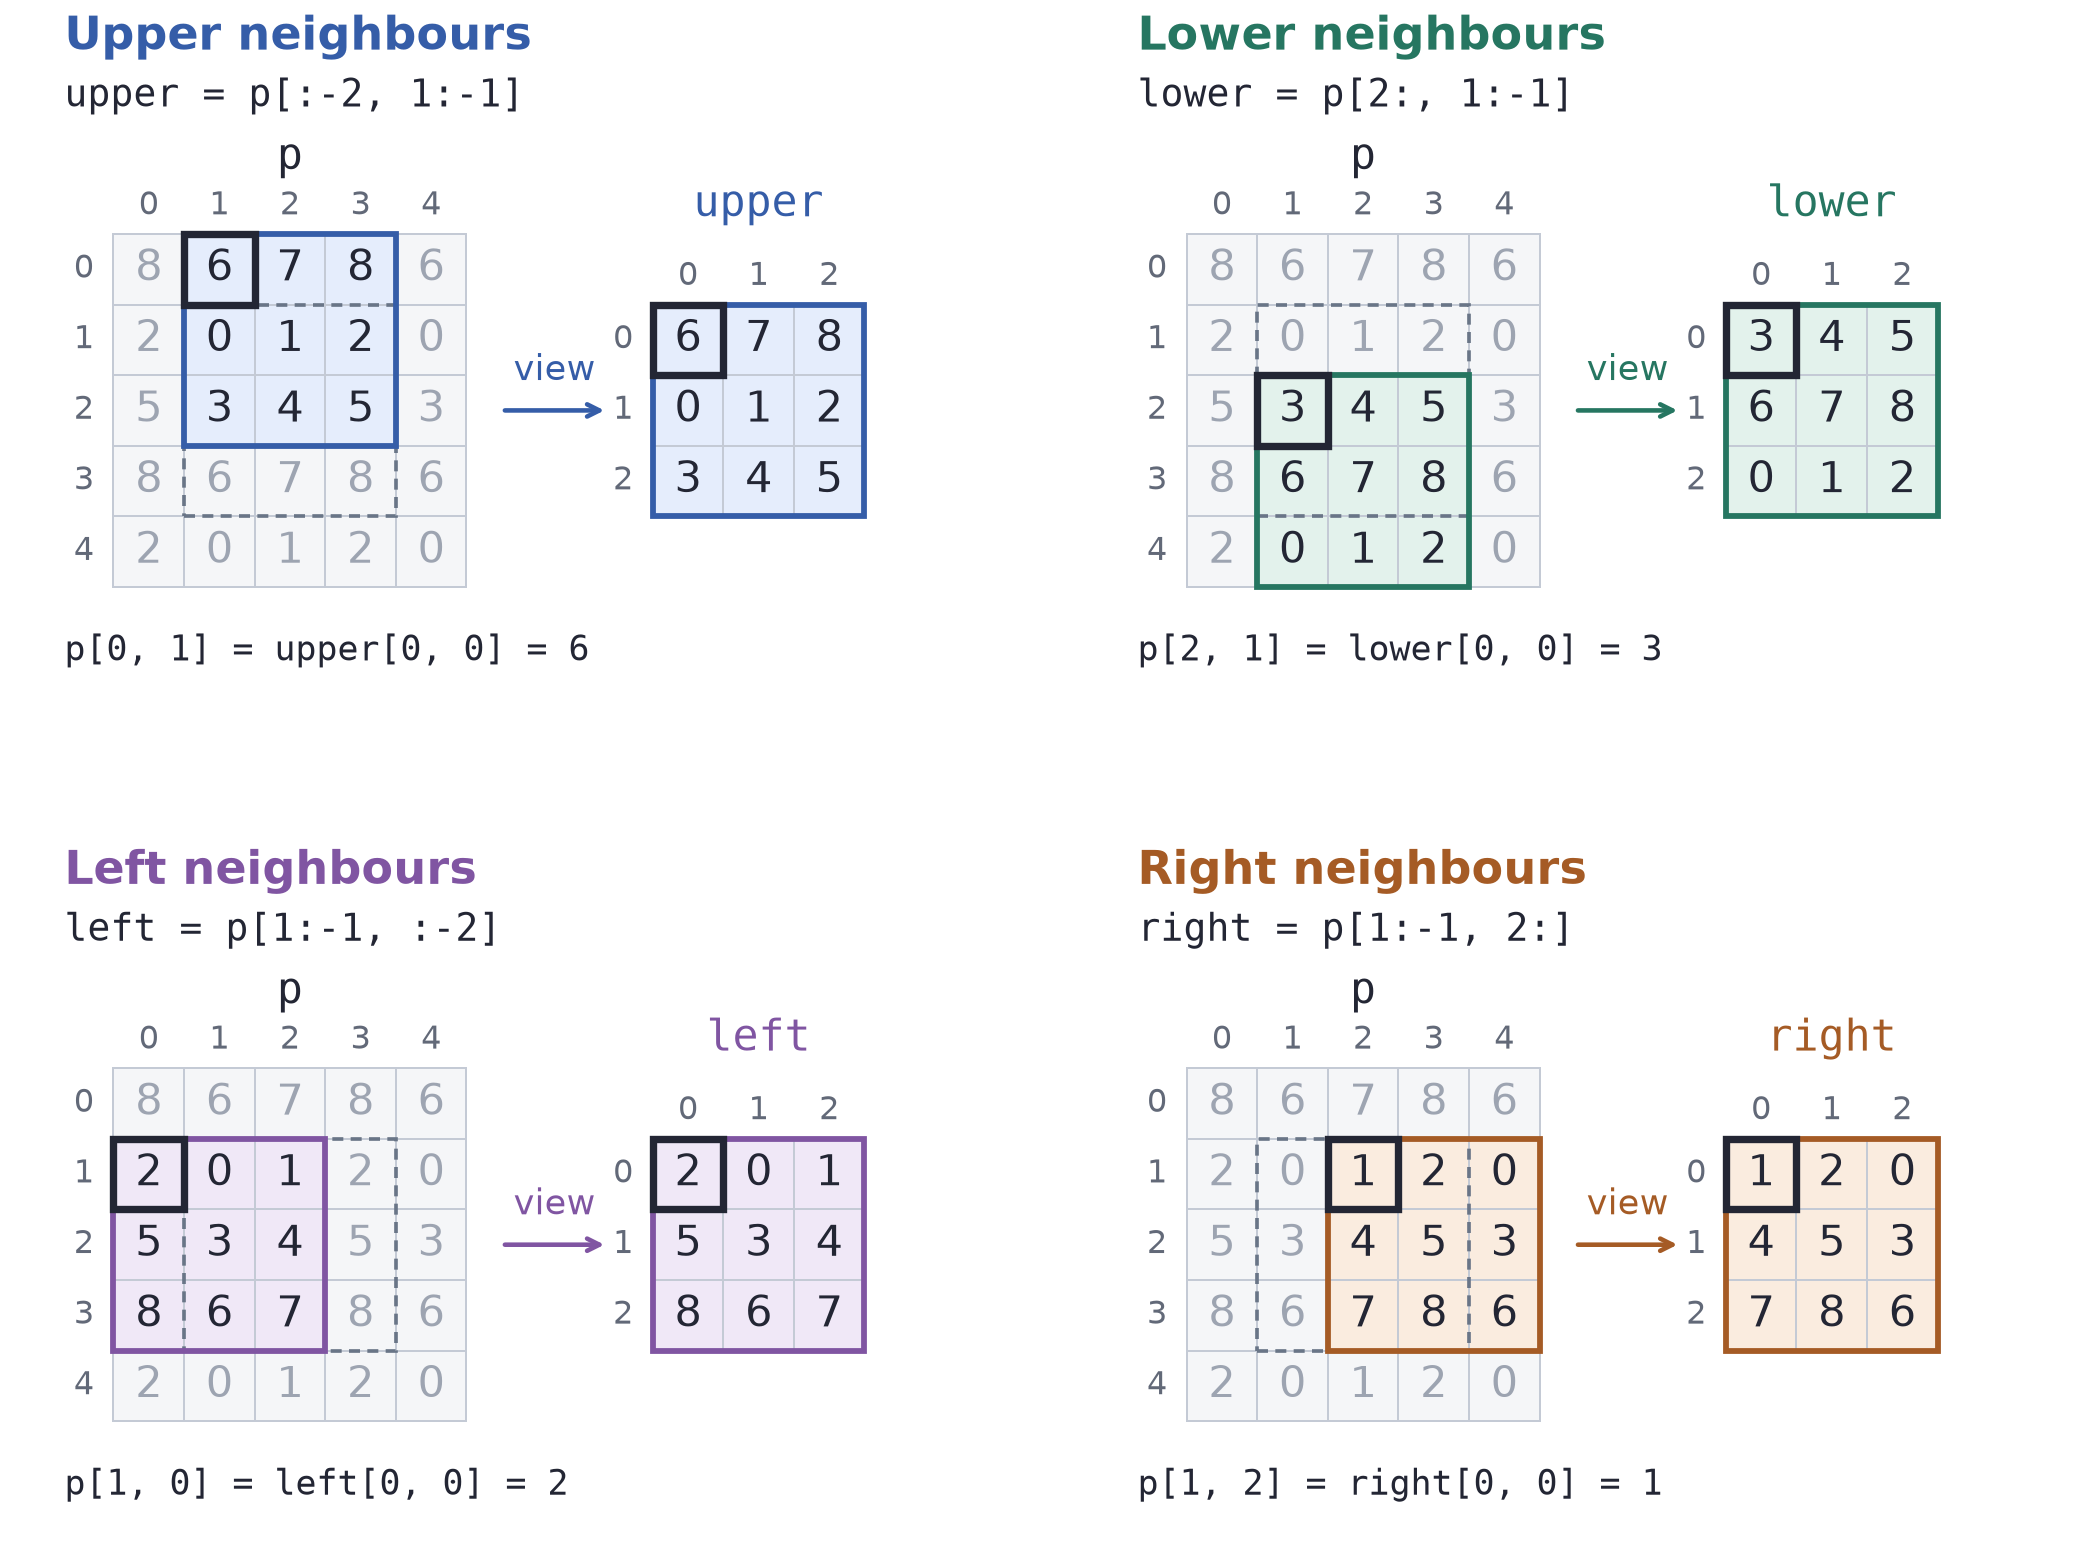

All four views have the shape of `a` and share storage with `p`. Creating these views does not copy their values. We now add corresponding entries and subtract four times the original array:

In [22]:
neighbour_sum = upper + lower + left + right
stencil_result = neighbour_sum - 4 * a
print('sum of neighbours:')
print(neighbour_sum)
print('discrete Laplacian:')
print(stencil_result)
np.testing.assert_array_equal(stencil_result, [[12, 9, 6], [3, 0, -3], [-6, -9, -12]])
np.testing.assert_array_equal(stencil_result, laplacian_loops(a))

sum of neighbours:
[[12. 13. 14.]
 [15. 16. 17.]
 [18. 19. 20.]]
discrete Laplacian:
[[ 12.   9.   6.]
 [  3.   0.  -3.]
 [ -6.  -9. -12.]]


![The outlined entry [0, 1] gives 7 + 4 + 0 + 2 − 4 × 1 = 9. The same elementwise calculation produces the entire discrete Laplacian for h = 1.](attachment:stencil_combination.png)

The outlined entry [0, 1] gives 7 + 4 + 0 + 2 − 4 × 1 = 9. The same elementwise calculation produces the entire discrete Laplacian for h = 1.
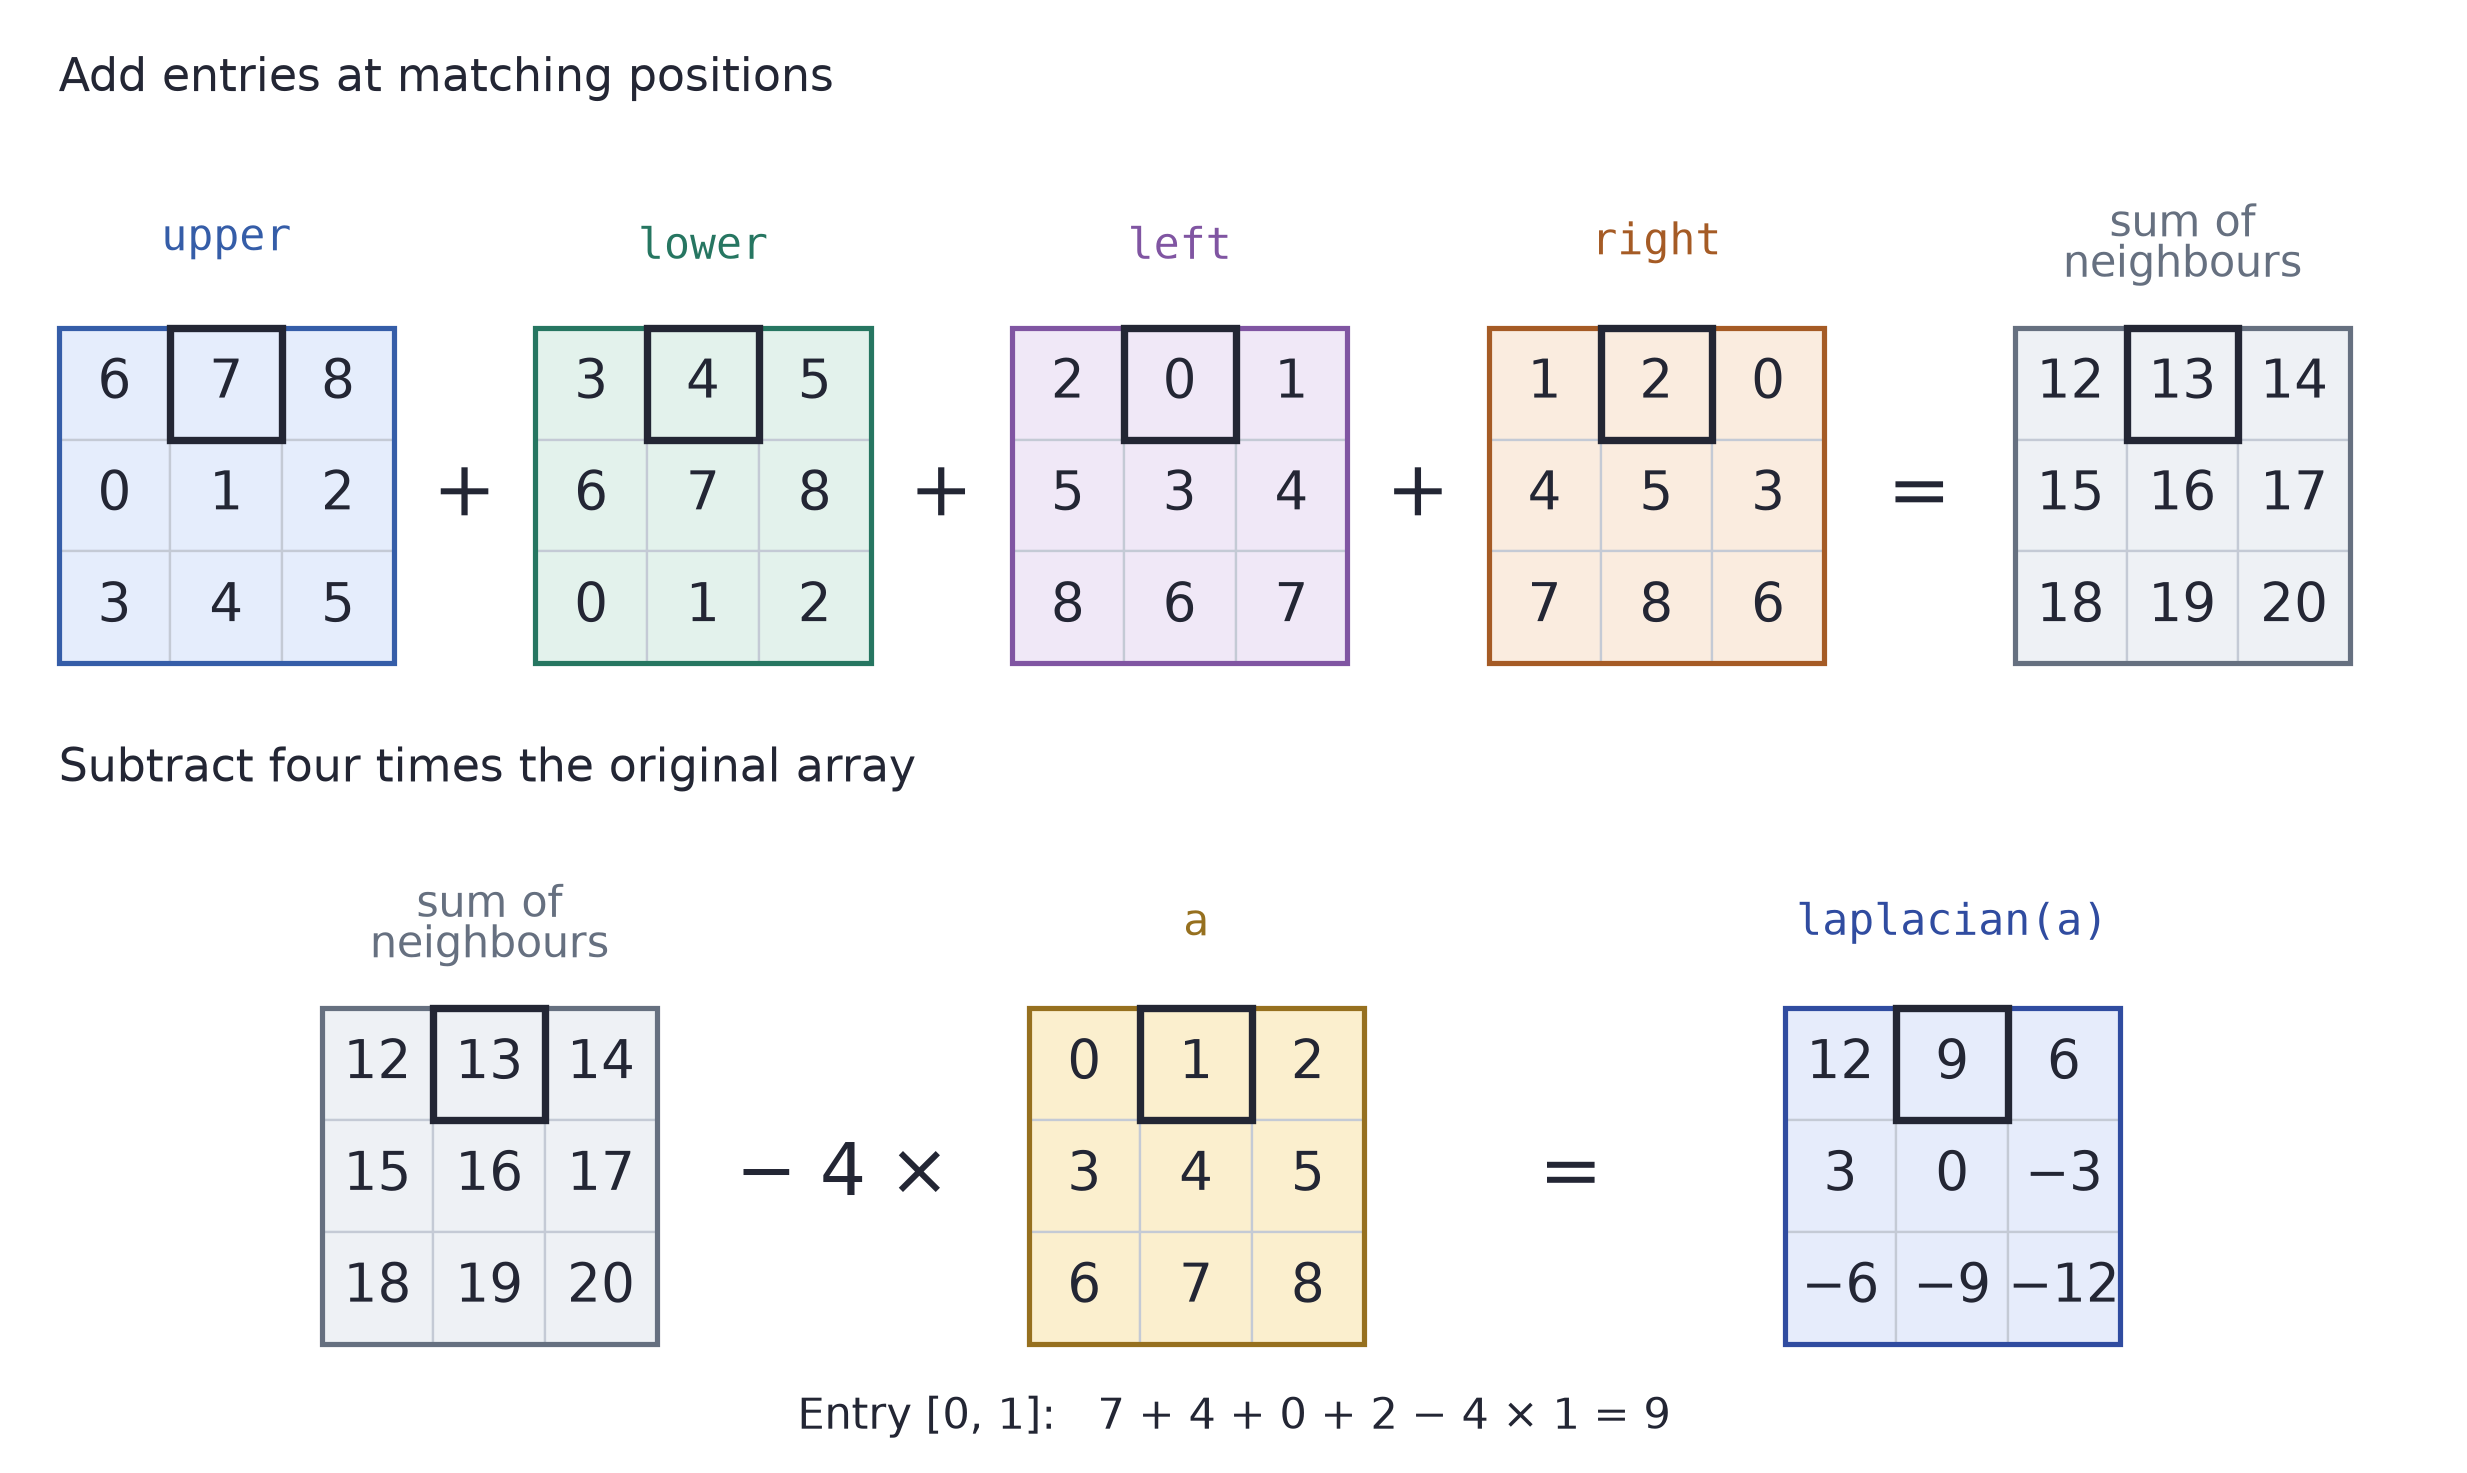

The implementation below pads only the final two axes, using the ellipsis from §2.4. For a two-dimensional array, `pad` is `[(1, 1), (1, 1)]`. For shape `(2, 256, 256)`, it is `[(0, 0), (1, 1), (1, 1)]`, leaving the first axis unchanged.

In [23]:
def laplacian(a):
    """Five-point Laplacian over the last two axes of a, with periodic boundaries.

    Parameters
    ----------
    a : numpy.ndarray
        Array of shape (..., n0, n1); the axes before the last two are a batch.

    Returns
    -------
    numpy.ndarray
        Array of the same shape as ``a``.

    Examples
    --------
    >>> a = np.zeros((3, 3)); a[1, 1] = 1.0
    >>> print(laplacian(a))
    [[ 0.  1.  0.]
     [ 1. -4.  1.]
     [ 0.  1.  0.]]
    """
    pad = [(0, 0)] * (a.ndim - 2) + [(1, 1), (1, 1)]
    p = np.pad(a, pad, mode="wrap")   # one layer of periodic copies around each grid
    return (p[..., :-2, 1:-1] + p[..., 2:, 1:-1]
            + p[..., 1:-1, :-2] + p[..., 1:-1, 2:] - 4 * a)

### 3.3. Checking and timing the implementation

Before timing the new implementation, we compare it with the loops on a non-square random grid. Different row and column lengths help reveal an accidental exchange of axes. We also check a constant field and an impulse, whose expected results follow directly from the stencil. Periodic diffusion should preserve the sum, and the uniform state u = 1, v = 0 should remain unchanged after a full model step.

In [24]:
test_grid = np.random.default_rng(1).random((5, 7))
expected = laplacian_loops(test_grid)
actual = laplacian(test_grid)
np.testing.assert_allclose(actual, expected, rtol=0, atol=1e-15)
np.testing.assert_array_equal(laplacian(np.ones((4, 6))), np.zeros((4, 6)))
np.testing.assert_array_equal(laplacian(impulse), [[0, 1, 0], [1, -4, 1], [0, 1, 0]])
np.testing.assert_allclose(laplacian(test_grid).sum(), 0, rtol=0, atol=1e-12)
np.testing.assert_array_equal(laplacian(a), stencil_result)
print('largest difference from loops:', np.max(np.abs(actual - expected)))
t_lap_loop = seconds(laplacian_loops, u, repeat=3)
t_lap_vector = seconds(laplacian, u)
print(f'loops: {1e3*t_lap_loop:.2f} ms; vectorised: {1e3*t_lap_vector:.3f} ms')
print(f'time ratio: {t_lap_loop/t_lap_vector:.1f}')

largest difference from loops: 0.0
loops: 25.54 ms; vectorised: 0.132 ms
time ratio: 193.0


This times one Laplacian, whereas §1.2 timed a complete Euler step with two Laplacians and reaction terms. The loop and vectorised versions both do $\Theta(N)$ work; the speedup comes from a more efficient implementation of the same algorithm.

## 4. Broadcasting

### 4.1. Combining different shapes

**Broadcasting** combines compatible shapes by reusing values. Compare the shapes from right to left: each pair of lengths must be equal or one must be 1. Missing leading axes count as length 1.

We subtract three column means from every row of a 2×3 array. The means have shape `(3,)`, interpreted as `(1, 3)` for this operation. The repeated means do not need storage, although the result does.

In [25]:
X = np.array([[1., 2., 3.], [3., 4., 5.]])
means = X.mean(axis=0)
print('means:', means)
print('centred values:')
print(X - means)
np.testing.assert_array_equal(X - means, [[-1, -1, -1], [1, 1, 1]])

means: [2. 3. 4.]
centred values:
[[-1. -1. -1.]
 [ 1.  1.  1.]]


We can also use broadcasting to divide each row by a different value: the first row by 1 and the second by 2. A length-two array has shape `(2,)`, which does not match the last axis of `X`, of length 3. We insert an axis of length 1 with `scale[:, None]`, giving shape `(2, 1)`. The values now align with the rows. We catch and display the first operation's `ValueError` so we can compare the two calls.

In [26]:
scale = np.array([1., 2.])
try:
    X / scale
except ValueError as error:
    print('ValueError:', error)
else:
    raise AssertionError('The incompatible shapes should fail')
print('scale[:, None]:', scale[:, None].shape)
print(scale[:, None])
print(X / scale[:, None])
np.testing.assert_array_equal(X / scale[:, None], [[1, 2, 3], [1.5, 2, 2.5]])

ValueError: operands could not be broadcast together with shapes (2,3) (2,) 
scale[:, None]: (2, 1)
[[1.]
 [2.]]
[[1.  2.  3. ]
 [1.5 2.  2.5]]


### 4.2. A batch of grids

We can use broadcasting to run several independent simulations, each with a particular pair $(F,k)$. Here $F$ is the feed rate of chemical $U$, and $k$ is the additional removal rate of chemical $V$.

Each simulation has two concentration grids. We collect them in arrays `u` and `v` of shape `(m, n, n)` for $m$ simulations. This collection is a **batch**. The first index selects a simulation: `u[0]` and `v[0]` are the two grids for the first parameter pair. The last two indices select a row and column within that grid.

For two pairs, `F` and `k` initially have shape `(2,)`. Adding two axes gives `(2, 1, 1)`, so each parameter value is reused over its own grid. `run` uses `np.broadcast_shapes` to determine the number of grids and `[..., None, None]` to prepare these parameter shapes. A scalar parameter can also be shared by all simulations.

The vectorised update uses the same equations as the loop version. We first check the uniform steady state, then compare one batched step with separate steps using exactly the same initial arrays. In these cells, `U` and `V` name the arrays containing the batch.

In [27]:
def step(u, v, F, k, Du=0.16, Dv=0.08, dt=1.0):
    """One forward Euler step of the Gray-Scott equations; returns new arrays.

    F and k are numbers, or arrays that broadcast against u and v.
    The pure-diffusion Euler bound is max(Du, Dv) * dt <= 1/4.
    Reactions can impose an additional restriction.
    """
    uvv = u * v * v
    return (u + dt * (Du * laplacian(u) - uvv + F * (1 - u)),
            v + dt * (Dv * laplacian(v) + uvv - (F + k) * v))

def run(F, k, n=256, steps=10_000, dt=1.0, seed=0):
    """u and v after `steps` steps, for one pair (F, k) or arrays of them.

    Examples
    --------
    >>> u, v = run([0.030, 0.040], [0.062, 0.060], n=32, steps=10)
    >>> v.shape
    (2, 32, 32)
    """
    F, k = np.asarray(F, dtype=float), np.asarray(k, dtype=float)
    batch = np.broadcast_shapes(F.shape, k.shape)
    u, v = initial(n, seed, batch)
    F, k = F[..., None, None], k[..., None, None]   # one value per grid, broadcast over its n x n points
    for _ in range(steps):
        u, v = step(u, v, F, k, dt=dt)
    return u, v

In [28]:
uniform_u, uniform_v = np.ones((8, 8)), np.zeros((8, 8))
steady_u, steady_v = step(uniform_u, uniform_v, *SPOTS)
np.testing.assert_array_equal(steady_u, uniform_u)
np.testing.assert_array_equal(steady_v, uniform_v)
print('uniform state remains unchanged')

U, V = initial(32, batch=(2,))
F = np.array([SPOTS[0], STRIPES[0]])
k = np.array([SPOTS[1], STRIPES[1]])
print('F:', F, 'broadcast shape:', F[:, None, None].shape)
print('k:', k, 'broadcast shape:', k[:, None, None].shape)
new_u, new_v = step(U, V, F[:, None, None], k[:, None, None])
for i in range(2):
    single_u, single_v = step(U[i], V[i], F[i], k[i])
    np.testing.assert_array_equal(new_u[i], single_u)
    np.testing.assert_array_equal(new_v[i], single_v)
print('batched and separate steps agree')

uniform state remains unchanged
F: [0.03 0.04] broadcast shape: (2, 1, 1)
k: [0.062 0.06 ] broadcast shape: (2, 1, 1)
batched and separate steps agree


We now run both parameter pairs for 10,000 steps of `dt=1`, reaching simulated time 10,000. Each grid starts with a central patch; the seeded generator supplies a separate noise realisation for each grid. This cell may take tens of seconds or longer, depending on the computer. There is no Python loop over simulations, but the loop over time remains because each step needs the previous state.

In [29]:
start = time.perf_counter()
U, V = run(F, k, n=256, steps=10_000)
print('field shape:', V.shape)
print(f'10,000 steps: {time.perf_counter()-start:.2f} s')
assert np.isfinite(U).all() and np.isfinite(V).all()

field shape: (2, 256, 256)
10,000 steps: 9.01 s


`V[0]` is the final concentration of chemical V for the first pair, and `V[1]` for the second. The plots use the same colour scale so their concentrations can be compared.

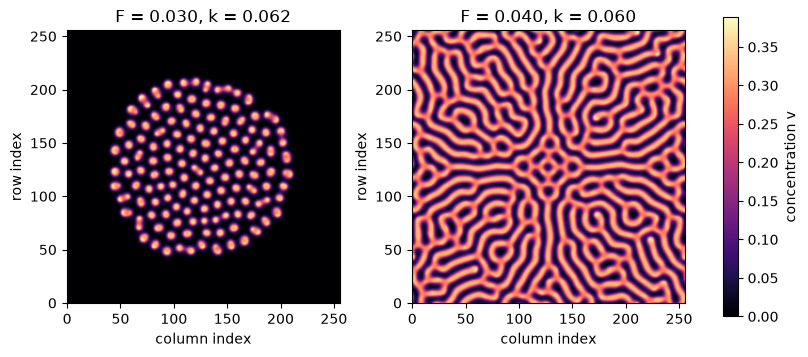

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')
for ax, field, feed, kill in zip(axes, V, F, k):
    im = ax.imshow(field, cmap='magma', origin='lower', vmin=0, vmax=V.max())
    ax.set_title(f'F = {feed:.3f}, k = {kill:.3f}')
    ax.set_xlabel('column index')
    ax.set_ylabel('row index')
fig.colorbar(im, ax=axes, label='concentration v')
plt.show()

## 5. Memory traffic and execution time

### 5.1. Counting array reads and writes

For float64 addition, each output requires two eight-byte reads and one eight-byte write: 24 bytes per element. This counts array accesses, not necessarily transfers from RAM; caches can satisfy some accesses.

For the stencil, we name the intermediate arrays to count their reads and writes. Each addition reads two values and writes one for every grid point:

In [31]:
t1 = upper + lower
t2 = t1 + left
t3 = t2 + right
t4 = 4 * a
out = t3 - t4
np.testing.assert_array_equal(out, stencil_result)
print(out)

[[ 12.   9.   6.]
 [  3.   0.  -3.]
 [ -6.  -9. -12.]]


We also count the copy into the padded array. Ignoring the extra entries in its thin boundary:

| Operation | Values read + written per point | Arithmetic operations per point |
|---|---:|---:|
| Padded copy | 2 | 0 |
| Three additions | 9 | 3 |
| Multiplication by 4 | 2 | 1 |
| Subtraction | 3 | 1 |
| Total | 16 | 5 |

The access count is approximately $16\times8=128$ bytes per point for float64. **Arithmetic intensity** is the number of arithmetic operations per byte transferred; our access model gives $5/128\simeq0.039$ operations per byte. The views themselves share storage, but padding and intermediate results still require writes.

At low intensity, we do little arithmetic compared with the data accessed: this example counts $128/5=25.6$ bytes per operation. If those accesses require RAM transfers, the processor may wait for data. High intensity means many operations per byte. For example, 100 operations per byte gives 100 million operations per 1 MB transferred. Reusing values held in registers or caches, as in matrix multiplication, can make this possible. Whether an intensity is high enough for arithmetic to dominate depends on the hardware ([NERSC explanation](https://docs.nersc.gov/tools/performance/roofline/)).

### 5.2. Memory-bound and compute-bound operations

A computation is **memory-bound** when data transfer limits its rate, and **compute-bound** when arithmetic throughput is the main limit. Comparing timings provides evidence, but does not by itself prove which hardware limit was reached.

The next cell reports median time per element after an untimed call. These expressions allocate their results. The 4096×4096 inputs occupy 128 MiB each; the stencil's intermediates bring its peak use to roughly 1 GiB. A smaller `large_n`, such as 2048, reduces that requirement. The untimed and timed calls can reuse cached data.

In [32]:
operations = {
    'copy': lambda a, b: a.copy(),
    'add': np.add,
    'divide': np.divide,
    'sqrt': lambda a, b: np.sqrt(a),
    'sin': lambda a, b: np.sin(a),
    'stencil': lambda a, b: laplacian(a),
}
print('size     ' + ''.join(f'{name:>12s}' for name in operations) + '  (ns/element)')
large_n = 4096
benchmark_ns = {}
for n in (256, large_n):
    a = np.random.default_rng(0).random((n, n))
    b = a + 1
    timings = [seconds(op, a, b, repeat=3) / a.size * 1e9 for op in operations.values()]
    benchmark_ns[n] = dict(zip(operations, timings))
    print(f'{n:4d}     ' + ''.join(f'{value:12.2f}' for value in timings))

size             copy         add      divide        sqrt         sin     stencil  (ns/element)
 256             0.10        0.22        0.22        0.27        2.80        2.23


4096             0.11        0.20        0.20        0.23        3.09        1.94


Array addition does little arithmetic per value, while evaluating sine requires more computation. We can also divide our addition access count by its measured time per element. This gives an effective transfer rate for the counting model, not a direct measurement of RAM bandwidth, because some accesses may be served by caches:

In [33]:
addition_seconds = benchmark_ns[large_n]['add'] * 1e-9
effective_gb_s = 24 / addition_seconds / 1e9
print(f'Addition access count / elapsed time: {effective_gb_s:.1f} GB/s')

Addition access count / elapsed time: 120.2 GB/s


### 5.3. Reusing an output array

`out=result` stores an operation's result in an existing array. We allocate it with `np.empty_like`, which does not initialise its entries, then overwrite them with `np.add`. Later calls can reuse this storage. The reads of the inputs and the writes of the result still occur.

In [34]:
a_small = np.array([1., 2., 3.])
b_small = np.array([4., 5., 6.])
result = np.empty_like(a_small)
returned = np.add(a_small, b_small, out=result)
print(result, 'same object:', returned is result)
assert returned is result
np.testing.assert_array_equal(result, [5, 7, 9])
output = np.empty_like(a)
t_new = seconds(np.add, a, b)
t_out = seconds(lambda: np.add(a, b, out=output))
print(f'new result: {1e3*t_new:.2f} ms; reused output: {1e3*t_out:.2f} ms')
np.testing.assert_array_equal(output, a + b)
del a, b, output

[5. 7. 9.] same object: True
new result: 3.37 ms; reused output: 3.37 ms


Compare the two measured times before concluding that reusing storage improved performance. For these large arrays, allocating a new result need not be the main cost. Timings vary between runs and computers.

## 6. Time stepping and stability

The **time step** $\Delta t$ advances the simulated time; the **grid spacing** $h$ separates neighbouring spatial points. A faster array implementation does not determine how large a time step we can use. We now check whether an Euler update damps or amplifies a fluctuation that diffusion should smooth out.

### 6.1. A checkerboard mode

For this example, $a_{ij}=(-1)^{i+j}$ is a deviation from a uniform concentration. The concentration field $c=1+0.05a$ alternates between 1.05 and 0.95. A negative entry of $a$ means below the background, not a negative concentration.

We use an even number of points in both directions, so signs alternate across the periodic boundary too. All four neighbours of each entry have the opposite sign. Applying the discrete Laplacian gives $L_h a=-8a/h^2$.

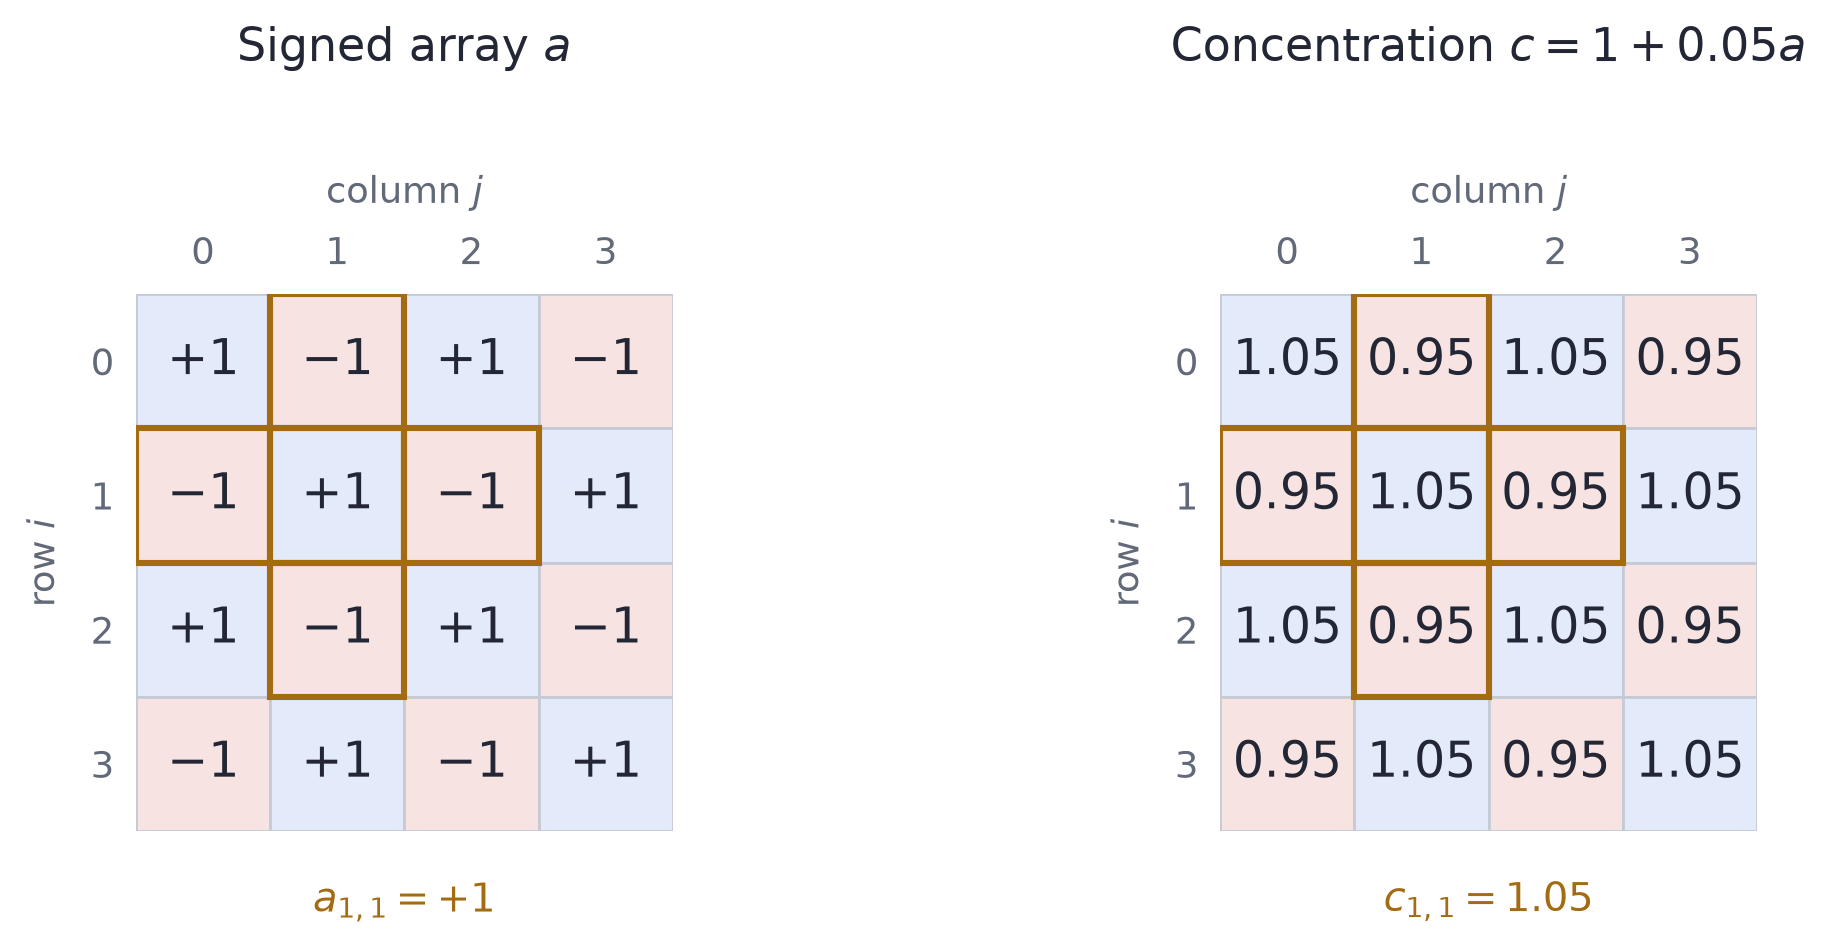

The signed checkerboard describes deviations around a positive background concentration. Its four opposite-sign neighbours give the most rapid spatial variation on this grid.

For pure diffusion with coefficient $D>0$, forward Euler multiplies this fluctuation by an **amplification factor**:

$$a^{\mathrm{new}}=a+D\Delta t L_h a
=\underbrace{\left(1-\frac{8D\Delta t}{h^2}\right)}_g a.$$

After $q$ steps, the amplitude has been multiplied by $|g|^q$. It decays for $|g|<1$ and grows for $|g|>1$. A negative $g$ also reverses the signs. At $g=-1$, signs alternate without any decrease in amplitude. Our code below uses $h=1$.

In [35]:
i, j = np.indices((8, 8))
checkerboard = (-1.0) ** (i + j)
np.testing.assert_array_equal(laplacian(checkerboard), -8 * checkerboard)
concentration = 1 + 0.05 * checkerboard
print('concentrations:', np.unique(concentration))
np.testing.assert_allclose(laplacian(concentration), 0.05 * laplacian(checkerboard))
D = 0.16
for dt in (1.0, 1.5625, 1.6):
    updated = checkerboard + D * dt * laplacian(checkerboard)
    factor = 1 - 8*D*dt
    np.testing.assert_allclose(updated, factor*checkerboard)
    print(f'dt={dt:g}: amplification factor={factor:g}')

concentrations: [0.95 1.05]
dt=1: amplification factor=-0.28
dt=1.5625: amplification factor=-1
dt=1.6: amplification factor=-1.048


Requiring $-1\leq g\leq1$ gives $D\Delta t/h^2\leq1/4$. The checkerboard changes sign between every pair of neighbours: it has the shortest spatial wavelength this grid can resolve. Diffusion damps these rapid variations fastest, so they impose the most restrictive Euler time step for this stencil.

With $D_u=0.16$ and $h=1$, the limiting step is 1.5625. Halving $h$ requires a fourfold reduction of $\Delta t$. This condition concerns pure diffusion; the reactions in Gray–Scott must also be considered.

### 6.2. Detecting instability in the full model

The pattern plots in §4.2 used time step $\Delta t=1$. We now examine what happens when we increase it in the same model. Each run uses a 128×128 grid, the same initial state (seed 0), and parameters F = 0.030 and k = 0.062. Only the time step changes. All runs attempt to reach the same simulated time T = 3000.

After each step we measure the largest absolute value in either concentration array. We stop if this exceeds 1000 or an entry becomes non-finite. The initial concentrations are of order 1; the threshold is a practical stop for a runaway calculation, not a mathematical stability criterion.

The helper below uses a shorter final step if needed to reach T exactly. The plot shows the recorded magnitudes and the alternating values when the dt = 1.6 run stops.

dt     steps       time       max |u| or |v|    outcome
1.00    3000    3000.00                  1    completed
1.50    2000    3000.00                  1    completed
1.55     425     658.75               1024    stopped
1.60     132     211.20               1001    stopped
Minimum u in the stopped dt=1.6 run: -990.53


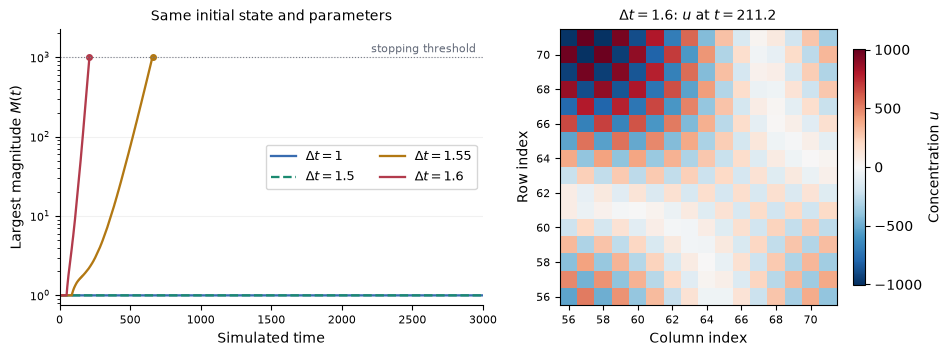

In [36]:
def stability_experiment(initial, step):
    """Return reports, histories and the final field of the dt=1.6 run."""
    final_time = 3000.0
    reports, histories = [], []
    for dt in (1.0, 1.5, 1.55, 1.6):
        u, v = initial(128, seed=0)
        time = 0.0
        times, magnitudes = [time], [float(max(abs(u).max(), abs(v).max()))]
        outcome = 'completed'
        for count in range(1, int(np.ceil(final_time / dt)) + 1):
            step_size = min(dt, final_time - time)
            u, v = step(u, v, 0.030, 0.062, dt=step_size)
            time = min(final_time, time + step_size)
            finite = bool(np.isfinite(u).all() and np.isfinite(v).all())
            peak = float(max(np.abs(u).max(), np.abs(v).max()))
            times.append(time)
            magnitudes.append(peak)
            if not finite or peak > 1000:
                outcome = 'stopped'
                break
        reports.append(dict(dt=dt, steps=count, time=time, max_abs=peak,
                            min_u=float(u.min()), finite=finite, outcome=outcome))
        histories.append((np.array(times), np.array(magnitudes)))
    return reports, histories, u

def plot_stability(reports, histories, last_u):
    """Plot magnitude growth and the spatial oscillation at the last stop."""
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.45), layout='constrained',
                             gridspec_kw={'width_ratios': [1.3, 1]})
    colours = ['#386cb0', '#1b8a70', '#b27813', '#b23b4c']
    styles = ['-', '--', '-', '-']
    ax = axes[0]
    for report, (times, values), colour, style in zip(reports, histories, colours, styles):
        ax.semilogy(times, values, color=colour, ls=style, lw=1.65,
                    label=rf'$\Delta t={report["dt"]:g}$')
        if report['outcome'] == 'stopped':
            ax.plot(times[-1], values[-1], 'o', color=colour, ms=4)
    ax.axhline(1000, color='#787c88', lw=0.8, ls=':')
    ax.text(2950, 1160, 'stopping threshold', ha='right', fontsize=8, color='#626978')
    ax.set(xlabel='Simulated time', ylabel=r'Largest magnitude $M(t)$',
           xlim=(0, 3000), ylim=(0.75, 2300), title='Same initial state and parameters')
    ax.legend(loc='center right', fontsize=9, ncol=2)
    ax.grid(axis='y', alpha=.17)
    ax.spines[['top', 'right']].set_visible(False)

    patch = last_u[56:72, 56:72]
    limit = np.max(np.abs(patch))
    im = axes[1].imshow(patch, cmap='RdBu_r', origin='lower',
                        vmin=-limit, vmax=limit, extent=(55.5,71.5,55.5,71.5))
    last = reports[-1]
    axes[1].set(xlabel='Column index', ylabel='Row index',
                title=rf'$\Delta t={last["dt"]:g}$: $u$ at $t={last["time"]:g}$')
    fig.colorbar(im, ax=axes[1], label=r'Concentration $u$', shrink=.85)
    for ax in axes:
        ax.tick_params(labelsize=8)
        ax.title.set_fontsize(10)
    return fig

reports, histories, last_u = stability_experiment(initial, step)
print('dt     steps       time       max |u| or |v|    outcome')
for report in reports:
    print(f'{report["dt"]:4.2f}   {report["steps"]:5d}   {report["time"]:8.2f}'
          f'   {report["max_abs"]:16.4g}    {report["outcome"]}')
print(f'Minimum u in the stopped dt=1.6 run: {reports[-1]["min_u"]:.2f}')
assert [r['outcome'] for r in reports] == ['completed', 'completed', 'stopped', 'stopped']
assert all(r['time'] == 3000 and r['finite'] for r in reports if r['outcome'] == 'completed')
fig = plot_stability(reports, histories, last_u)
plt.show()

The 1.55 and 1.6 runs develop very large values of alternating sign. The negative concentrations printed and plotted above are nonphysical. The final plot zooms in on the central patch so we can see the rapid oscillation between neighbouring points.

The failure at 1.55, below the pure-diffusion limit 1.5625, shows why we must also consider the feed and reaction terms. Around $u=1$, $v=0$, write $u=1+\varepsilon$ for a small checkerboard perturbation. The feed term becomes $F(1-u)=-F\varepsilon$. Adding this contribution to the diffusion update gives

$$g = 1-(8D_u+F)\Delta t = 1-1.31\Delta t.$$

At dt = 1.55, this is -1.0305, which amplifies the perturbation. The diffusion-only bound does not suffice for the full model.

The two completed runs did not trigger our stopping rule before T = 3000. That does not establish accuracy. To assess error from time stepping, compare results at the same final time with smaller steps, keeping the grid and initial state fixed.

### 6.3. Implicit methods

Refining a diffusion grid can force explicit methods to take very small steps even when the pattern evolves slowly. This is a common source of **stiffness**. An implicit method can permit larger stable steps.

For pure diffusion, backward Euler evaluates the stencil at the unknown new state:

$$a^{\mathrm{new}} = a + D\Delta t L_h a^{\mathrm{new}}.$$

We must solve the coupled equations for the new grid values. For the checkerboard, $L_h a^{\mathrm{new}}=-8a^{\mathrm{new}}/h^2$, giving

$$a^{\mathrm{new}} = \frac{a}{1+8D\Delta t/h^2}.$$

The amplification factor is between 0 and 1 for every positive step. We can compare the factors directly, without implementing a full implicit solver:

In [37]:
D, h, dt = 0.16, 1.0, 1.6
g_explicit = 1 - 8 * D * dt / h**2
g_implicit = 1 / (1 + 8 * D * dt / h**2)
print(f'Forward Euler factor: {g_explicit:.3f}')
print(f'Backward Euler factor: {g_implicit:.3f}')
assert abs(g_explicit) > 1 and 0 < g_implicit < 1

Forward Euler factor: -1.048
Backward Euler factor: 0.328


Backward Euler damps this fluctuation, but a stable large step need not be accurate. Each step also costs more because it requires solving equations. For pure diffusion these equations are linear. If the nonlinear reaction terms are also treated implicitly, we need a nonlinear solve at each step.

### 6.4. Adaptive time steps

An adaptive solver estimates the error of each trial step. It rejects a step whose estimated error is too large and retries with a smaller one. After accepting a step, it may increase the next step size. We choose absolute and relative tolerances for this local error control.

Adaptive stepping is standard in general-purpose ODE solvers. It is separate from the choice of explicit or implicit method: [SciPy's solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) offers adaptive explicit RK45 for non-stiff problems and adaptive implicit Radau and BDF for stiff problems. Adaptivity alone does not remove an explicit method's stability restriction.

Here the fixed-step implementation lets us examine the array operations and stability limit. In a research calculation, we should select a suitable solver and check convergence by tightening tolerances or reducing the step size.

The notes contain exercises with worked solutions on strides, shapes, array-access counts and the pure-diffusion step-size limit.